In [53]:
# ============================================================
# Stage 4 - Step 1.1 : Import Libraries
# ============================================================

import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("Disease Classification using SegFusionFormer")
print("=" * 60)

print("PyTorch Version :", torch.__version__)
print("OpenCV Version  :", cv2.__version__)

Disease Classification using SegFusionFormer
PyTorch Version : 2.10.0
OpenCV Version  : 4.13.0


In [54]:
# ============================================================
# Stage 4 - Step 1.2 : Device Configuration
# ============================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple Silicon GPU (MPS)"
elif torch.cuda.is_available():
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)
else:
    device = torch.device("cpu")
    device_name = "CPU"

print("=" * 60)
print("Device Configuration")
print("=" * 60)

print(f"Device      : {device}")
print(f"Description : {device_name}")

Device Configuration
Device      : mps
Description : Apple Silicon GPU (MPS)


In [55]:
# ============================================================
# Stage 4 - Step 1.3 : Project Paths
# ============================================================

# Project Root
PROJECT_ROOT = Path.home() / "Desktop" / "Mtech_final_project" / "SegFusionFormer"

# Dataset
dataset_dir = PROJECT_ROOT / "dataset"

images_dir = dataset_dir / "images"
masks_dir = dataset_dir / "lung_masks"

csv_path = dataset_dir / "Data_Entry_2017.csv"

# Models
models_dir = PROJECT_ROOT / "models"

# Outputs
outputs_dir = PROJECT_ROOT / "outputs"

print("=" * 70)
print("Project Paths")
print("=" * 70)

print("Project Root :", PROJECT_ROOT)
print("Images       :", images_dir)
print("Lung Masks   :", masks_dir)
print("CSV File     :", csv_path)
print("Models       :", models_dir)
print("Outputs      :", outputs_dir)

print("\nFolder Status")
print("-" * 70)

print("Images Exists :", images_dir.exists())
print("Masks Exists  :", masks_dir.exists())
print("CSV Exists    :", csv_path.exists())
print("Models Exists :", models_dir.exists())
print("Outputs Exists:", outputs_dir.exists())

Project Paths
Project Root : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer
Images       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Lung Masks   : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks
CSV File     : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/Data_Entry_2017.csv
Models       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models
Outputs      : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs

Folder Status
----------------------------------------------------------------------
Images Exists : True
Masks Exists  : True
CSV Exists    : True
Models Exists : True
Outputs Exists: True


In [56]:
# ============================================================
# Stage 4 - Step 2.1 : Read NIH ChestX-ray14 Labels
# ============================================================

# Read CSV
df = pd.read_csv(csv_path)

print("=" * 70)
print("NIH ChestX-ray14 Dataset")
print("=" * 70)

print("Number of Images :", len(df))
print("Number of Columns:", len(df.columns))

print("\nColumns")
print("-" * 70)

for col in df.columns:
    print(col)

NIH ChestX-ray14 Dataset
Number of Images : 112120
Number of Columns: 12

Columns
----------------------------------------------------------------------
Image Index
Finding Labels
Follow-up #
Patient ID
Patient Age
Patient Gender
View Position
OriginalImage[Width
Height]
OriginalImagePixelSpacing[x
y]
Unnamed: 11


In [57]:
# Remove unwanted empty columns
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("Columns after cleaning:", len(df.columns))
print(df.columns)

Columns after cleaning: 11
Index(['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID',
       'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width',
       'Height]', 'OriginalImagePixelSpacing[x', 'y]'],
      dtype='object')


In [58]:
display(df.head())

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143


In [59]:
# ============================================================
# Stage 4 - Step 3.1 : Define NIH Disease Classes
# ============================================================

DISEASES = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

print("=" * 60)
print("NIH Disease Classes")
print("=" * 60)

for i, disease in enumerate(DISEASES):
    print(f"{i+1:2d}. {disease}")

NIH Disease Classes
 1. Atelectasis
 2. Cardiomegaly
 3. Effusion
 4. Infiltration
 5. Mass
 6. Nodule
 7. Pneumonia
 8. Pneumothorax
 9. Consolidation
10. Edema
11. Emphysema
12. Fibrosis
13. Pleural_Thickening
14. Hernia


In [60]:
# ============================================================
# Stage 4 - Step 3.2 : Exact Multi-Label Encoding
# ============================================================

# Split each Finding Labels entry into its exact labels
label_sets = df["Finding Labels"].fillna("").apply(
    lambda x: set(x.split("|"))
)

# Create one binary column for each disease
for disease in DISEASES:
    df[disease] = label_sets.apply(
        lambda labels: 1.0 if disease in labels else 0.0
    ).astype(np.float32)

print("=" * 60)
print("Exact Multi-label Encoding Completed")
print("=" * 60)

print(df[DISEASES].head())

Exact Multi-label Encoding Completed
   Atelectasis  Cardiomegaly  Effusion  Infiltration  Mass  Nodule  Pneumonia  \
0          0.0           1.0       0.0           0.0   0.0     0.0        0.0   
1          0.0           1.0       0.0           0.0   0.0     0.0        0.0   
2          0.0           1.0       1.0           0.0   0.0     0.0        0.0   
3          0.0           0.0       0.0           0.0   0.0     0.0        0.0   
4          0.0           0.0       0.0           0.0   0.0     0.0        0.0   

   Pneumothorax  Consolidation  Edema  Emphysema  Fibrosis  \
0           0.0            0.0    0.0        0.0       0.0   
1           0.0            0.0    0.0        1.0       0.0   
2           0.0            0.0    0.0        0.0       0.0   
3           0.0            0.0    0.0        0.0       0.0   
4           0.0            0.0    0.0        0.0       0.0   

   Pleural_Thickening  Hernia  
0                 0.0     0.0  
1                 0.0     0.0  
2      

In [61]:
# ============================================================
# Stage 4 - Step 3.3 : Disease Distribution
# ============================================================

print("=" * 60)
print("Disease Distribution")
print("=" * 60)

disease_counts = df[DISEASES].sum().sort_values(ascending=False)

print(disease_counts)

Disease Distribution
Infiltration          19894.0
Effusion              13317.0
Atelectasis           11559.0
Nodule                 6331.0
Mass                   5782.0
Pneumothorax           5302.0
Consolidation          4667.0
Pleural_Thickening     3385.0
Cardiomegaly           2776.0
Emphysema              2516.0
Edema                  2303.0
Fibrosis               1686.0
Pneumonia              1431.0
Hernia                  227.0
dtype: float32


In [62]:
# ============================================================
# Stage 4 - Step 3.4 : Verify Encoding
# ============================================================

print("=" * 80)
print("Sample Encoded Labels")
print("=" * 80)

for i in range(5):
    print(f"\nImage : {df.loc[i, 'Image Index']}")
    print(f"Labels: {df.loc[i, 'Finding Labels']}")
    print(df.loc[i, DISEASES])

Sample Encoded Labels

Image : 00000001_000.png
Labels: Cardiomegaly
Atelectasis           0.0
Cardiomegaly          1.0
Effusion              0.0
Infiltration          0.0
Mass                  0.0
Nodule                0.0
Pneumonia             0.0
Pneumothorax          0.0
Consolidation         0.0
Edema                 0.0
Emphysema             0.0
Fibrosis              0.0
Pleural_Thickening    0.0
Hernia                0.0
Name: 0, dtype: object

Image : 00000001_001.png
Labels: Cardiomegaly|Emphysema
Atelectasis           0.0
Cardiomegaly          1.0
Effusion              0.0
Infiltration          0.0
Mass                  0.0
Nodule                0.0
Pneumonia             0.0
Pneumothorax          0.0
Consolidation         0.0
Edema                 0.0
Emphysema             1.0
Fibrosis              0.0
Pleural_Thickening    0.0
Hernia                0.0
Name: 1, dtype: object

Image : 00000001_002.png
Labels: Cardiomegaly|Effusion
Atelectasis           0.0
Cardiomegaly      

In [63]:
# ============================================================
# Stage 4 - Define Project Paths
# ============================================================

from pathlib import Path

# Project root folder
project_root = Path.home() / "Desktop" / "Mtech_final_project" / "SegFusionFormer"

print("=" * 60)
print("Project Root")
print("=" * 60)
print(project_root)

Project Root
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer


In [64]:
# ============================================================
# Stage 4 – Step 4.1 : Create Image & Lung Mask Paths
# ============================================================

from pathlib import Path

# NIH image folder
nih_images_dir = project_root / "dataset" / "images"

# Generated lung masks (Stage 3)
lung_masks_dir = project_root / "dataset" / "lung_masks"

print("=" * 60)
print("Dataset Paths")
print("=" * 60)

print("Images Folder    :", nih_images_dir)
print("Masks Folder     :", lung_masks_dir)

# Create full paths
df["image_path"] = df["Image Index"].apply(
    lambda x: nih_images_dir / x
)

df["mask_path"] = df["Image Index"].apply(
    lambda x: lung_masks_dir / f"{Path(x).stem}_mask.png"
)

print("\nSample Paths")
print(df[["Image Index","image_path","mask_path"]].head())

Dataset Paths
Images Folder    : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Masks Folder     : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks

Sample Paths
        Image Index                                         image_path  \
0  00000001_000.png  /Users/solomonrajan/Desktop/Mtech_final_projec...   
1  00000001_001.png  /Users/solomonrajan/Desktop/Mtech_final_projec...   
2  00000001_002.png  /Users/solomonrajan/Desktop/Mtech_final_projec...   
3  00000002_000.png  /Users/solomonrajan/Desktop/Mtech_final_projec...   
4  00000003_000.png  /Users/solomonrajan/Desktop/Mtech_final_projec...   

                                           mask_path  
0  /Users/solomonrajan/Desktop/Mtech_final_projec...  
1  /Users/solomonrajan/Desktop/Mtech_final_projec...  
2  /Users/solomonrajan/Desktop/Mtech_final_projec...  
3  /Users/solomonrajan/Desktop/Mtech_final_projec...  
4  /Users/solomonrajan/Desktop/Mtech_final_projec...

In [65]:
# ============================================================
# Stage 4 – Step 4.2 : Verify Image-Mask Pairs
# ============================================================

print("=" * 60)
print("Verifying Dataset Files")
print("=" * 60)

df["image_exists"] = df["image_path"].apply(lambda x: x.exists())
df["mask_exists"] = df["mask_path"].apply(lambda x: x.exists())

print("Images Found :", df["image_exists"].sum())
print("Masks Found  :", df["mask_exists"].sum())

print("\nMissing Images :", (~df["image_exists"]).sum())
print("Missing Masks  :", (~df["mask_exists"]).sum())

Verifying Dataset Files
Images Found : 112120
Masks Found  : 112120

Missing Images : 0
Missing Masks  : 0


In [66]:
# ============================================================
# Stage 4 – Step 4.3 : Keep Only Valid Samples
# ============================================================

df = df[
    df["image_exists"] &
    df["mask_exists"]
].reset_index(drop=True)

print("=" * 60)
print("Final Dataset Size")
print("=" * 60)

print("Valid Samples :", len(df))

Final Dataset Size
Valid Samples : 112120


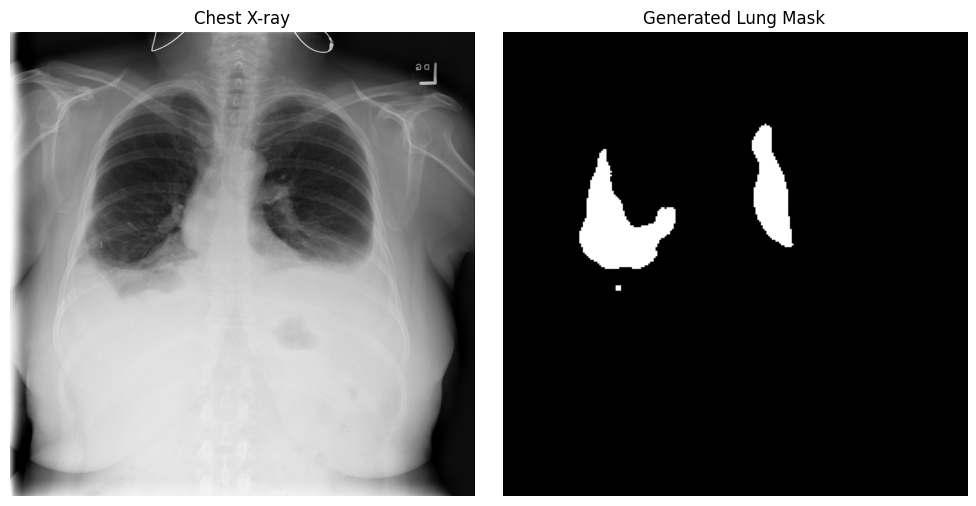

Disease Labels
Effusion


In [67]:
# ============================================================
# Stage 4 – Step 4.4 : Visual Verification
# ============================================================

import matplotlib.pyplot as plt
import cv2

sample = df.sample(1).iloc[0]

image = cv2.imread(
    str(sample.image_path),
    cv2.IMREAD_GRAYSCALE
)

mask = cv2.imread(
    str(sample.mask_path),
    cv2.IMREAD_GRAYSCALE
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image, cmap="gray")
plt.title("Chest X-ray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask, cmap="gray")
plt.title("Generated Lung Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("="*60)
print("Disease Labels")
print("="*60)

print(sample["Finding Labels"])

In [68]:
# ============================================================
# Stage 4 – Step 5 : DiseaseClassificationDataset
# ============================================================

import cv2
import torch
import numpy as np
from torch.utils.data import Dataset

IMG_SIZE = 224


class DiseaseClassificationDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # -----------------------------
        # Read Chest X-ray
        # -----------------------------
        image = cv2.imread(
            str(row.image_path),
            cv2.IMREAD_GRAYSCALE
        )

        # -----------------------------
        # Read Lung Mask
        # -----------------------------
        mask = cv2.imread(
            str(row.mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        # -----------------------------
        # Resize
        # -----------------------------
        image = cv2.resize(
            image,
            (IMG_SIZE, IMG_SIZE)
        )

        mask = cv2.resize(
            mask,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        # -----------------------------
        # Normalize
        # -----------------------------
        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        mask = (mask > 0.5).astype(np.float32)

        # -----------------------------
        # Convert to tensors
        # -----------------------------
        image = torch.tensor(image).unsqueeze(0)
        mask = torch.tensor(mask).unsqueeze(0)

        # -----------------------------
        # Segmentation-Guided Input
        # 2 channels:
        # Channel 1 -> Chest X-ray
        # Channel 2 -> Lung Mask
        # -----------------------------
        x = torch.cat([image, mask], dim=0)

        # -----------------------------
        # Multi-label Target
        # -----------------------------
        y = torch.tensor(
            row[DISEASES].values.astype(np.float32)
        )

        return x, y

In [69]:
# ============================================================
# Stage 4 – Step 5.1 : Test Dataset
# ============================================================

dataset = DiseaseClassificationDataset(df)

x, y = dataset[0]

print("=" * 60)
print("Dataset Test")
print("=" * 60)

print("Input Shape :", x.shape)
print("Label Shape :", y.shape)

print("\nImage Channel Range")
print(x[0].min().item(), "to", x[0].max().item())

print("\nMask Channel Values")
print(torch.unique(x[1]))

print("\nDisease Labels")
print(y)

Dataset Test
Input Shape : torch.Size([2, 224, 224])
Label Shape : torch.Size([14])

Image Channel Range
0.0 to 1.0

Mask Channel Values
tensor([0., 1.])

Disease Labels
tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


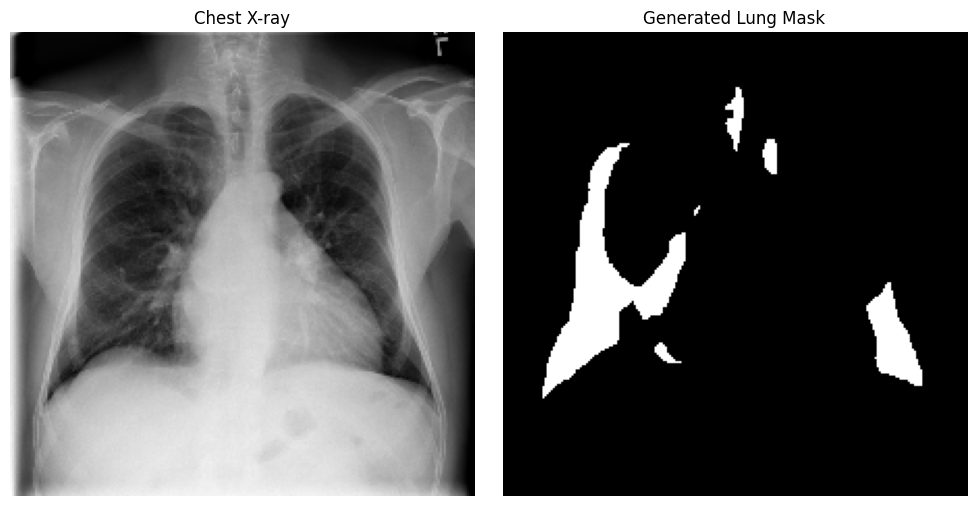

Positive Diseases
Cardiomegaly


In [70]:
# ============================================================
# Stage 4 – Step 5.2 : Visualize Dataset Sample
# ============================================================

import matplotlib.pyplot as plt

x, y = dataset[0]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(x[0], cmap="gray")
plt.title("Chest X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(x[1], cmap="gray")
plt.title("Generated Lung Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("=" * 60)
print("Positive Diseases")
print("=" * 60)

for disease, value in zip(DISEASES, y):
    if value == 1:
        print(disease)

In [71]:
# ============================================================
# Stage 4 – Step 6 : Train / Validation Split
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 60)
print("Creating Train / Validation Split")
print("=" * 60)

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Training Samples   : {len(train_df)}")
print(f"Validation Samples : {len(val_df)}")

Creating Train / Validation Split
Training Samples   : 89696
Validation Samples : 22424


In [72]:
# ============================================================
# Stage 4 – Step 6.1 : Create Dataset Objects
# ============================================================

train_dataset = DiseaseClassificationDataset(train_df)
val_dataset = DiseaseClassificationDataset(val_df)

print("=" * 60)
print("Dataset Objects Created")
print("=" * 60)

print("Train Dataset :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))

Dataset Objects Created
Train Dataset : 89696
Validation Dataset : 22424


In [73]:
# ============================================================
# Stage 4 – Step 6.2 : Create DataLoaders
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("=" * 60)
print("DataLoaders Created")
print("=" * 60)

print("Batch Size :", BATCH_SIZE)
print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))

DataLoaders Created
Batch Size : 8
Train Batches : 11212
Validation Batches : 2803


In [74]:
# ============================================================
# Stage 4 – Step 6.3 : Verify One Batch
# ============================================================

images, labels = next(iter(train_loader))

print("=" * 60)
print("Batch Verification")
print("=" * 60)

print("Images Shape :", images.shape)
print("Labels Shape :", labels.shape)

print("\nImage Range")
print(images.min().item(), "to", images.max().item())

print("\nMask Channel Values")
print(torch.unique(images[:, 1]))

print("\nFirst Sample Labels")
print(labels[0])

Batch Verification
Images Shape : torch.Size([8, 2, 224, 224])
Labels Shape : torch.Size([8, 14])

Image Range
0.0 to 1.0

Mask Channel Values
tensor([0., 1.])

First Sample Labels
tensor([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])


In [75]:
# ============================================================
# Stage 4 – Step 7.1 : Import Libraries
# ============================================================

import torch
import torch.nn as nn
import torchvision.models as models

print("=" * 60)
print("Libraries Imported")
print("=" * 60)

print("PyTorch :", torch.__version__)

Libraries Imported
PyTorch : 2.10.0


In [76]:
# ============================================================
# Stage 4 – Step 7.2 : CNN Backbone
# ============================================================

class CNNBackbone(nn.Module):

    def __init__(self):

        super().__init__()

        backbone = models.efficientnet_b0(weights="DEFAULT")

        # Accept 2-channel input (X-ray + Lung Mask)
        backbone.features[0][0] = nn.Conv2d(
            2,
            32,
            kernel_size=3,
            stride=2,
            padding=1,
            bias=False
        )

        self.features = backbone.features

    def forward(self, x):

        return self.features(x)

In [77]:
# ============================================================
# Stage 4 – Step 7.3 : Test CNN Backbone
# ============================================================

cnn = CNNBackbone().to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    features = cnn(images)

print("=" * 60)
print("CNN Backbone Test")
print("=" * 60)

print("Input Shape  :", images.shape)
print("Output Shape :", features.shape)
print("Device       :", features.device)

CNN Backbone Test
Input Shape  : torch.Size([8, 2, 224, 224])
Output Shape : torch.Size([8, 1280, 7, 7])
Device       : mps:0


In [78]:
# ============================================================
# Stage 4 – Step 7.4 : Feature Projection
# ============================================================

class FeatureProjection(nn.Module):

    def __init__(self,
                 in_channels=1280,
                 embed_dim=768):

        super().__init__()

        self.project = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=1
        )

    def forward(self, x):

        return self.project(x)

In [79]:
# ============================================================
# Stage 4 – Step 7.5 : Test Projection
# ============================================================

projection = FeatureProjection().to(device)

with torch.no_grad():
    projected = projection(features)

print("=" * 60)
print("Projection Test")
print("=" * 60)

print("Projected Shape :", projected.shape)

Projection Test
Projected Shape : torch.Size([8, 768, 7, 7])


In [80]:
# ============================================================
# Stage 4 – Step 7.6 : Patch Embedding
# ============================================================

class PatchEmbedding(nn.Module):

    def forward(self, x):

        B, C, H, W = x.shape

        x = x.flatten(2)

        x = x.transpose(1, 2)

        return x

In [81]:
# ============================================================
# Stage 4 – Step 7.7 : Test Patch Embedding
# ============================================================

patch = PatchEmbedding()

tokens = patch(projected)

print("=" * 60)
print("Patch Embedding Test")
print("=" * 60)

print("Token Shape :", tokens.shape)

Patch Embedding Test
Token Shape : torch.Size([8, 49, 768])


In [82]:
# ============================================================
# Stage 4 – Step 7.8 : Transformer Encoder
# ============================================================

class TransformerEncoder(nn.Module):

    def __init__(self,
                 embed_dim=768,
                 num_heads=8,
                 depth=4):

        super().__init__()

        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            layer,
            num_layers=depth
        )

    def forward(self, x):

        return self.encoder(x)

In [83]:
# ============================================================
# Stage 4 – Step 7.9 : Test Transformer
# ============================================================

transformer = TransformerEncoder().to(device)

tokens = tokens.to(device)

with torch.no_grad():
    output = transformer(tokens)

print("=" * 60)
print("Transformer Test")
print("=" * 60)

print("Input Tokens :", tokens.shape)
print("Output Tokens:", output.shape)

Transformer Test
Input Tokens : torch.Size([8, 49, 768])
Output Tokens: torch.Size([8, 49, 768])


In [84]:
# ============================================================
# Stage 4 – Step 8.1 : Feature Fusion Module
# ============================================================

import torch
import torch.nn as nn

class FeatureFusion(nn.Module):

    def __init__(self,
                 cnn_dim=1280,
                 transformer_dim=768,
                 fusion_dim=1024):

        super().__init__()

        # CNN branch
        self.cnn_pool = nn.AdaptiveAvgPool2d(1)

        self.cnn_fc = nn.Linear(
            cnn_dim,
            fusion_dim // 2
        )

        # Transformer branch
        self.transformer_fc = nn.Linear(
            transformer_dim,
            fusion_dim // 2
        )

        # Final fusion
        self.fusion = nn.Sequential(

            nn.Linear(
                fusion_dim,
                fusion_dim
            ),

            nn.ReLU(inplace=True),

            nn.Dropout(0.3)
        )

    def forward(self,
                cnn_features,
                transformer_tokens):

        # ------------------------
        # CNN Global Feature
        # ------------------------
        cnn = self.cnn_pool(cnn_features)

        cnn = cnn.flatten(1)

        cnn = self.cnn_fc(cnn)

        # ------------------------
        # Transformer Global Feature
        # ------------------------
        transformer = transformer_tokens.mean(dim=1)

        transformer = self.transformer_fc(transformer)

        # ------------------------
        # Concatenate
        # ------------------------
        fused = torch.cat(
            [cnn, transformer],
            dim=1
        )

        fused = self.fusion(fused)

        return fused

In [85]:
# ============================================================
# Stage 4 – Step 8.2 : Test Feature Fusion
# ============================================================

fusion = FeatureFusion().to(device)

with torch.no_grad():

    fused_features = fusion(
        features,
        output
    )

print("=" * 60)
print("Feature Fusion Test")
print("=" * 60)

print("CNN Features      :", features.shape)
print("Transformer Tokens:", output.shape)
print("Fused Features    :", fused_features.shape)

Feature Fusion Test
CNN Features      : torch.Size([8, 1280, 7, 7])
Transformer Tokens: torch.Size([8, 49, 768])
Fused Features    : torch.Size([8, 1024])


In [86]:
# ============================================================
# Stage 4 – Step 8.3 : Device Verification
# ============================================================

print("=" * 60)
print("Device Verification")
print("=" * 60)

print("CNN Device        :", features.device)
print("Transformer Device:", output.device)
print("Fusion Device     :", fused_features.device)

Device Verification
CNN Device        : mps:0
Transformer Device: mps:0
Fusion Device     : mps:0


In [87]:
# ============================================================
# Stage 4 – Step 8.4 : Feature Statistics
# ============================================================

print("=" * 60)
print("Fusion Feature Statistics")
print("=" * 60)

print("Shape :", fused_features.shape)

print("Mean  :", fused_features.mean().item())

print("Std   :", fused_features.std().item())

print("Min   :", fused_features.min().item())

print("Max   :", fused_features.max().item())

Fusion Feature Statistics
Shape : torch.Size([8, 1024])
Mean  : 0.06504573673009872
Std   : 0.12592312693595886
Min   : 0.0
Max   : 0.8188527822494507


In [88]:
# ============================================================
# Stage 4 – Step 7 : Mask-Guided Attention Module
# ============================================================

import torch
import torch.nn as nn


class MaskGuidedAttention(nn.Module):

    def __init__(self):
        super().__init__()

        # Learnable attention generator
        self.attention_generator = nn.Sequential(

            nn.Conv2d(
                in_channels=2,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(16),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                in_channels=16,
                out_channels=8,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                in_channels=8,
                out_channels=1,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

        # Learnable strength of mask-guided attention
        self.alpha = nn.Parameter(
            torch.tensor(1.0)
        )


    def forward(self, x):

        # -----------------------------------------
        # Separate X-ray and lung mask
        # -----------------------------------------

        image = x[:, 0:1, :, :]

        mask = x[:, 1:2, :, :]


        # -----------------------------------------
        # Generate learned attention map
        # -----------------------------------------

        learned_attention = self.attention_generator(x)


        # -----------------------------------------
        # Anatomical mask guidance
        # -----------------------------------------

        guided_attention = (
            learned_attention * mask
        )


        # -----------------------------------------
        # Enhance lung-region information
        # -----------------------------------------

        enhanced_image = image * (
            1.0 + self.alpha * guided_attention
        )


        # Keep image intensity stable
        enhanced_image = torch.clamp(
            enhanced_image,
            0.0,
            1.0
        )


        # -----------------------------------------
        # Convert grayscale → 3 channels
        # Required by pretrained CNN / MaxViT
        # -----------------------------------------

        enhanced_rgb = enhanced_image.repeat(
            1,
            3,
            1,
            1
        )


        return (
            enhanced_rgb,
            guided_attention
        )

In [89]:
# ============================================================
# Stage 4 – Step 7.1 : Test Mask-Guided Attention
# ============================================================

mask_attention = MaskGuidedAttention().to(device)

# Get one batch
inputs, labels = next(iter(train_loader))

inputs = inputs.to(device)

# Forward pass
with torch.no_grad():

    enhanced_images, attention_maps = mask_attention(
        inputs
    )


print("=" * 60)
print("Mask-Guided Attention Test")
print("=" * 60)

print("Original Input :", inputs.shape)

print(
    "Enhanced Image:",
    enhanced_images.shape
)

print(
    "Attention Map :",
    attention_maps.shape
)

print("\nEnhanced Range:")
print(
    enhanced_images.min().item(),
    "to",
    enhanced_images.max().item()
)

print("\nDevice:")
print(enhanced_images.device)

Mask-Guided Attention Test
Original Input : torch.Size([8, 2, 224, 224])
Enhanced Image: torch.Size([8, 3, 224, 224])
Attention Map : torch.Size([8, 1, 224, 224])

Enhanced Range:
0.0 to 1.0

Device:
mps:0


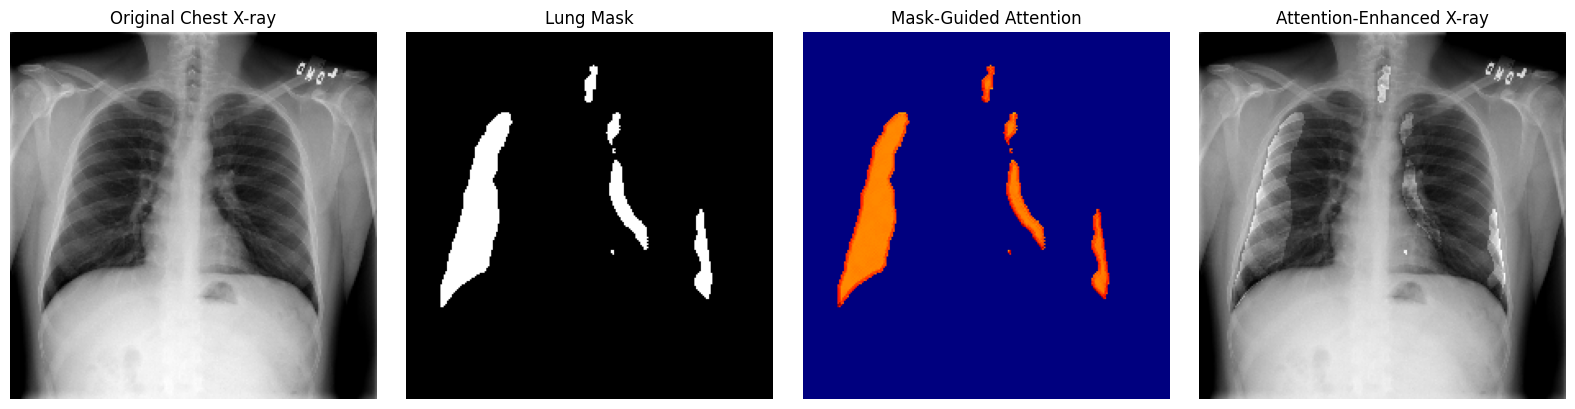

In [90]:
# ============================================================
# Stage 4 – Step 7.2 : Visualize Mask-Guided Attention
# ============================================================

inputs_cpu = inputs.cpu()
enhanced_cpu = enhanced_images.cpu()
attention_cpu = attention_maps.cpu()

sample = 0

plt.figure(figsize=(16, 4))

# Original X-ray
plt.subplot(1, 4, 1)

plt.imshow(
    inputs_cpu[sample, 0],
    cmap="gray"
)

plt.title("Original Chest X-ray")
plt.axis("off")


# Lung Mask
plt.subplot(1, 4, 2)

plt.imshow(
    inputs_cpu[sample, 1],
    cmap="gray"
)

plt.title("Lung Mask")
plt.axis("off")


# Attention Map
plt.subplot(1, 4, 3)

plt.imshow(
    attention_cpu[sample, 0],
    cmap="jet"
)

plt.title("Mask-Guided Attention")
plt.axis("off")


# Enhanced X-ray
plt.subplot(1, 4, 4)

plt.imshow(
    enhanced_cpu[sample, 0],
    cmap="gray"
)

plt.title("Attention-Enhanced X-ray")
plt.axis("off")


plt.tight_layout()
plt.show()

In [91]:
%pip install timm

Note: you may need to restart the kernel to use updated packages.


In [92]:
# ============================================================
# Stage 4 – Step 8.1 : Import Backbone Libraries
# ============================================================

import timm
import torchvision.models as models

print("timm version:", timm.__version__)

timm version: 1.0.25


In [93]:
# ============================================================
# Stage 4 – Step 8.2 : EfficientNet-B0 CNN Branch
# ============================================================

class EfficientNetBranch(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        # Remove final classifier
        self.features = backbone.features

        # Global pooling
        self.pool = nn.AdaptiveAvgPool2d(1)

        # EfficientNet-B0 final feature dimension
        self.feature_dim = 1280

    def forward(self, x):

        x = self.features(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        return x

In [94]:
# ============================================================
# Stage 4 – Step 8.3 : Test EfficientNet Branch
# ============================================================

cnn_branch = EfficientNetBranch().to(device)

with torch.no_grad():

    cnn_features = cnn_branch(
        enhanced_images
    )

print("=" * 60)
print("EfficientNet-B0 Branch Test")
print("=" * 60)

print("Input Shape :", enhanced_images.shape)
print("CNN Features:", cnn_features.shape)
print("Device      :", cnn_features.device)

EfficientNet-B0 Branch Test
Input Shape : torch.Size([8, 3, 224, 224])
CNN Features: torch.Size([8, 1280])
Device      : mps:0


In [95]:
# ============================================================
# Stage 4 – Step 8.4 : MaxViT Branch
# ============================================================

class MaxViTBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = timm.create_model(
            "maxvit_tiny_tf_224.in1k",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.feature_dim = self.backbone.num_features

    def forward(self, x):

        x = self.backbone(x)

        return x

In [96]:
# ============================================================
# Stage 4 – Step 8.5 : Test MaxViT Branch
# ============================================================

maxvit_branch = MaxViTBranch().to(device)

with torch.no_grad():

    maxvit_features = maxvit_branch(
        enhanced_images
    )

print("=" * 60)
print("MaxViT Branch Test")
print("=" * 60)

print("Input Shape    :", enhanced_images.shape)
print("MaxViT Features:", maxvit_features.shape)
print("Feature Dim    :", maxvit_branch.feature_dim)
print("Device         :", maxvit_features.device)

MaxViT Branch Test
Input Shape    : torch.Size([8, 3, 224, 224])
MaxViT Features: torch.Size([8, 512])
Feature Dim    : 512
Device         : mps:0


In [97]:
# ============================================================
# Stage 4 – Step 8.6 : Dual Branch Test
# ============================================================

with torch.no_grad():

    cnn_features = cnn_branch(
        enhanced_images
    )

    maxvit_features = maxvit_branch(
        enhanced_images
    )

print("=" * 70)
print("Dual Feature Extraction Test")
print("=" * 70)

print("Enhanced Input :", enhanced_images.shape)
print("CNN Features   :", cnn_features.shape)
print("MaxViT Features:", maxvit_features.shape)

print("\nFeature Dimensions")
print("CNN    :", cnn_branch.feature_dim)
print("MaxViT :", maxvit_branch.feature_dim)

Dual Feature Extraction Test
Enhanced Input : torch.Size([8, 3, 224, 224])
CNN Features   : torch.Size([8, 1280])
MaxViT Features: torch.Size([8, 512])

Feature Dimensions
CNN    : 1280
MaxViT : 512


In [98]:
# ============================================================
# Stage 4 – Step 9.1 : Adaptive Feature Fusion Module
# CORRECTED VERSION
# ============================================================

import torch
import torch.nn as nn
import torchvision.models as models
class AdaptiveFeatureFusion(nn.Module):

    def __init__(
        self,
        cnn_dim,
        maxvit_dim,
        fusion_dim=512,
        dropout=0.3
    ):
        super().__init__()

        # Project CNN features
        self.cnn_projection = nn.Sequential(
            nn.Linear(cnn_dim, fusion_dim),
            nn.ReLU(inplace=True)
        )

        # Project MaxViT features
        self.maxvit_projection = nn.Sequential(
            nn.Linear(maxvit_dim, fusion_dim),
            nn.ReLU(inplace=True)
        )

        # Adaptive gate
        self.gate = nn.Sequential(
            nn.Linear(fusion_dim * 2, fusion_dim),
            nn.ReLU(inplace=True),
            nn.Linear(fusion_dim, 2),
            nn.Softmax(dim=1)
        )

        # Final refinement
        self.refine = nn.Sequential(
            nn.LayerNorm(fusion_dim),
            nn.Dropout(dropout)
        )

    def forward(self, cnn_features, maxvit_features):

        # Project both branches
        cnn_proj = self.cnn_projection(cnn_features)
        maxvit_proj = self.maxvit_projection(maxvit_features)

        # Combine for gate calculation
        combined = torch.cat(
            [cnn_proj, maxvit_proj],
            dim=1
        )

        # Adaptive weights
        weights = self.gate(combined)

        cnn_weight = weights[:, 0:1]
        maxvit_weight = weights[:, 1:2]

        # Weighted fusion
        fused = (
            cnn_weight * cnn_proj
            +
            maxvit_weight * maxvit_proj
        )

        # Refine
        fused = self.refine(fused)

        # VERY IMPORTANT
        return fused, weights

In [99]:
# ============================================================
# Stage 4 – Step 9.2 : Instantiate Fusion Module
# ============================================================
print(cnn_branch)
print(maxvit_branch)
fusion_module = AdaptiveFeatureFusion(
    cnn_dim=cnn_branch.feature_dim,
    maxvit_dim=maxvit_branch.feature_dim,
    fusion_dim=512,
    dropout=0.3
).to(device)

print("=" * 60)
print("Adaptive Feature Fusion Created")
print("=" * 60)

print("CNN Feature Dim    :", cnn_branch.feature_dim)
print("MaxViT Feature Dim :", maxvit_branch.feature_dim)
print("Fusion Dim         :", 512)

EfficientNetBranch(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormA

In [100]:
# ============================================================
# Stage 4 – Step 9.3 : Test Adaptive Feature Fusion
# ============================================================

fusion_module.eval()

with torch.no_grad():

    fused_features, fusion_weights = fusion_module(
        cnn_features,
        maxvit_features
    )

print("=" * 70)
print("Adaptive Feature Fusion Test")
print("=" * 70)

print("CNN Features    :", cnn_features.shape)
print("MaxViT Features :", maxvit_features.shape)
print("Fused Features  :", fused_features.shape)
print("Fusion Weights  :", fusion_weights.shape)

print("\nFirst Sample Weights")

print(
    "CNN Weight    :",
    fusion_weights[0, 0].item()
)

print(
    "MaxViT Weight :",
    fusion_weights[0, 1].item()
)

print(
    "\nWeight Sum    :",
    fusion_weights[0].sum().item()
)

Adaptive Feature Fusion Test
CNN Features    : torch.Size([8, 1280])
MaxViT Features : torch.Size([8, 512])
Fused Features  : torch.Size([8, 512])
Fusion Weights  : torch.Size([8, 2])

First Sample Weights
CNN Weight    : 0.49023810029029846
MaxViT Weight : 0.5097619295120239

Weight Sum    : 1.0


In [103]:
# ==========================================================
# Stage 4 – Step 9.4 : Complete SegFusionFormer
# CORRECTED VERSION
# ==========================================================

class SegFusionFormer(nn.Module):

    def __init__(self, num_classes=14):
        super().__init__()

        # --------------------------------------------
        # Mask-Guided Attention
        # Input: [B, 2, 224, 224]
        # Output: enhanced RGB image [B, 3, 224, 224]
        # --------------------------------------------
        self.mask_attention = MaskGuidedAttention()

        # --------------------------------------------
        # Dual Feature Extraction Branches
        # --------------------------------------------
        self.cnn_branch = EfficientNetBranch()

        self.maxvit_branch = MaxViTBranch()

        # --------------------------------------------
        # Adaptive Feature Fusion
        # --------------------------------------------
        self.fusion = AdaptiveFeatureFusion(
            cnn_dim=self.cnn_branch.feature_dim,
            maxvit_dim=self.maxvit_branch.feature_dim,
            fusion_dim=512,
            dropout=0.3
        )

        # --------------------------------------------
        # Multi-label Classification Head
        # --------------------------------------------
        self.classifier = nn.Sequential(

            nn.LayerNorm(512),

            nn.Linear(512, 256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # x shape:
        # [B, 2, 224, 224]
        #
        # Channel 0 = Chest X-ray
        # Channel 1 = Lung mask

        # --------------------------------------------
        # Mask-Guided Attention
        # --------------------------------------------
        enhanced_image, attention_map = self.mask_attention(x)

        # --------------------------------------------
        # EfficientNet Branch
        # --------------------------------------------
        cnn_features = self.cnn_branch(
            enhanced_image
        )

        # --------------------------------------------
        # MaxViT Branch
        # --------------------------------------------
        maxvit_features = self.maxvit_branch(
            enhanced_image
        )

        # --------------------------------------------
        # Adaptive Feature Fusion
        # --------------------------------------------
        fused_features, fusion_weights = self.fusion(
            cnn_features,
            maxvit_features
        )

        # --------------------------------------------
        # Classification
        # --------------------------------------------
        logits = self.classifier(
            fused_features
        )

        return logits, fusion_weights, attention_map


print("✅ SegFusionFormer class created successfully.")

✅ SegFusionFormer class created successfully.


In [105]:
# ==========================================================
# Stage 4 – Step 9.5 : Test Complete SegFusionFormer
# CORRECTED VERSION
# ==========================================================

print("=" * 70)
print("Testing Complete SegFusionFormer")
print("=" * 70)

# --------------------------------------------
# Create complete model
# --------------------------------------------
model = SegFusionFormer(
    num_classes=len(DISEASES)
).to(device)

model.eval()

# --------------------------------------------
# Get one batch
# Dataset returns:
# inputs -> [B, 2, 224, 224]
# labels -> [B, 14]
# --------------------------------------------
inputs, labels = next(iter(train_loader))

inputs = inputs.to(device)
labels = labels.to(device)

# --------------------------------------------
# Forward Pass
# --------------------------------------------
with torch.no_grad():

    logits, fusion_weights, attention_maps = model(
        inputs
    )

# --------------------------------------------
# Results
# --------------------------------------------
print("\nInput Shape")
print("------------")
print("Inputs :", inputs.shape)
print("Labels :", labels.shape)

print("\nModel Output")
print("------------")
print("Logits         :", logits.shape)
print("Fusion Weights :", fusion_weights.shape)
print("Attention Maps :", attention_maps.shape)

# Convert logits to probabilities
probabilities = torch.sigmoid(logits)

print("\nFirst Sample Fusion Weights")
print("---------------------------")

print(
    "CNN Weight    :",
    fusion_weights[0, 0].item()
)

print(
    "MaxViT Weight :",
    fusion_weights[0, 1].item()
)

print(
    "Weight Sum    :",
    fusion_weights[0].sum().item()
)

print("\nFirst Sample Prediction Probabilities")
print("-------------------------------------")

for disease, probability in zip(
    DISEASES,
    probabilities[0].cpu()
):

    print(
        f"{disease:20s}: "
        f"{probability.item():.4f}"
    )

print("\nDevice Check")
print("------------")

print("Input Device :", inputs.device)
print(
    "Model Device :",
    next(model.parameters()).device
)

print("\n✅ Complete forward pass successful.")

Testing Complete SegFusionFormer

Input Shape
------------
Inputs : torch.Size([8, 2, 224, 224])
Labels : torch.Size([8, 14])

Model Output
------------
Logits         : torch.Size([8, 14])
Fusion Weights : torch.Size([8, 2])
Attention Maps : torch.Size([8, 1, 224, 224])

First Sample Fusion Weights
---------------------------
CNN Weight    : 0.5024986863136292
MaxViT Weight : 0.4975012540817261
Weight Sum    : 0.9999999403953552

First Sample Prediction Probabilities
-------------------------------------
Atelectasis         : 0.4665
Cardiomegaly        : 0.4917
Effusion            : 0.4448
Infiltration        : 0.5539
Mass                : 0.4985
Nodule              : 0.4674
Pneumonia           : 0.4774
Pneumothorax        : 0.5369
Consolidation       : 0.4804
Edema               : 0.4726
Emphysema           : 0.5157
Fibrosis            : 0.4813
Pleural_Thickening  : 0.4998
Hernia              : 0.5095

Device Check
------------
Input Device : mps:0
Model Device : mps:0

✅ Complete fo

In [106]:
# ==========================================================
# Stage 4 – Step 10 : Weighted BCE Loss
# ==========================================================

import torch
import torch.nn as nn

print("=" * 70)
print("Creating Weighted BCEWithLogitsLoss")
print("=" * 70)

# ----------------------------------------------------------
# Compute positive counts for each disease
# ----------------------------------------------------------

positive_counts = df[DISEASES].sum().values

# Negative counts
negative_counts = len(df) - positive_counts

# ----------------------------------------------------------
# pos_weight = Negative / Positive
# ----------------------------------------------------------

pos_weights = torch.tensor(
    negative_counts / positive_counts,
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights
)

print("\nLoss Function Created Successfully\n")

print("Positive Weights")

for disease, weight in zip(DISEASES, pos_weights):

    print(f"{disease:20s}: {weight.item():.2f}")

print("\nDevice :", pos_weights.device)

Creating Weighted BCEWithLogitsLoss

Loss Function Created Successfully

Positive Weights
Atelectasis         : 8.70
Cardiomegaly        : 39.39
Effusion            : 7.42
Infiltration        : 4.64
Mass                : 18.39
Nodule              : 16.71
Pneumonia           : 77.35
Pneumothorax        : 20.15
Consolidation       : 23.02
Edema               : 47.68
Emphysema           : 43.56
Fibrosis            : 65.50
Pleural_Thickening  : 32.12
Hernia              : 492.92

Device : mps:0


In [107]:
# ==========================================================
# Stage 4 – Step 11 : Optimizer & Scheduler
# ==========================================================

import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR

print("=" * 70)
print("Creating Optimizer and Scheduler")
print("=" * 70)

# ----------------------------------------------------------
# AdamW Optimizer
# ----------------------------------------------------------

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ----------------------------------------------------------
# Cosine Annealing Scheduler
# ----------------------------------------------------------

NUM_EPOCHS = 20

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=1e-6
)

# ----------------------------------------------------------
# Automatic Mixed Precision (AMP)
# ----------------------------------------------------------

# AMP is currently most useful on CUDA.
# Disable automatically on Apple MPS or CPU.

use_amp = (device.type == "cuda")

if use_amp:
    scaler = torch.cuda.amp.GradScaler()
else:
    scaler = None

print("\nOptimizer")
print("---------")
print(optimizer)

print("\nScheduler")
print("---------")
print(type(scheduler).__name__)

print("\nConfiguration")
print("-------------")
print("Learning Rate :", optimizer.param_groups[0]["lr"])
print("Weight Decay  :", optimizer.param_groups[0]["weight_decay"])
print("Epochs        :", NUM_EPOCHS)
print("AMP Enabled   :", use_amp)
print("Device        :", device)

Creating Optimizer and Scheduler

Optimizer
---------
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0001
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)

Scheduler
---------
CosineAnnealingLR

Configuration
-------------
Learning Rate : 0.0001
Weight Decay  : 0.0001
Epochs        : 20
AMP Enabled   : False
Device        : mps


In [108]:
# ==========================================================
# Stage 4 – Step 12 : Training Function
# ==========================================================

from tqdm.auto import tqdm


def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device,
    scaler=None,
    use_amp=False
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for inputs, labels in progress_bar:

        # --------------------------------------------------
        # Move data to device
        # --------------------------------------------------
        inputs = inputs.to(device)
        labels = labels.to(device)

        batch_size = inputs.size(0)

        # --------------------------------------------------
        # Clear old gradients
        # --------------------------------------------------
        optimizer.zero_grad(set_to_none=True)

        # --------------------------------------------------
        # CUDA AMP path
        # --------------------------------------------------
        if use_amp and scaler is not None:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits, fusion_weights, attention_maps = model(
                    inputs
                )

                loss = criterion(
                    logits,
                    labels
                )

            scaler.scale(loss).backward()

            scaler.step(optimizer)

            scaler.update()

        # --------------------------------------------------
        # MPS / CPU path
        # --------------------------------------------------
        else:

            logits, fusion_weights, attention_maps = model(
                inputs
            )

            loss = criterion(
                logits,
                labels
            )

            loss.backward()

            optimizer.step()

        # --------------------------------------------------
        # Track loss
        # --------------------------------------------------
        running_loss += loss.item() * batch_size
        total_samples += batch_size

        average_loss = (
            running_loss / total_samples
        )

        progress_bar.set_postfix(
            loss=f"{average_loss:.4f}"
        )

    # ------------------------------------------------------
    # Final epoch loss
    # ------------------------------------------------------
    epoch_loss = (
        running_loss / total_samples
    )

    return epoch_loss

In [109]:
# ==========================================================
# Stage 4 – Step 13 : Validation Function
# ==========================================================

import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)


def validate_one_epoch(
    model,
    dataloader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probs = []

    with torch.no_grad():

        progress_bar = tqdm(
            dataloader,
            desc="Validation",
            leave=False
        )

        for inputs, labels in progress_bar:

            inputs = inputs.to(device)
            labels = labels.to(device)

            batch_size = inputs.size(0)

            logits, _, _ = model(inputs)

            loss = criterion(
                logits,
                labels
            )

            running_loss += loss.item() * batch_size
            total_samples += batch_size

            probs = torch.sigmoid(logits)

            all_probs.append(
                probs.cpu().numpy()
            )

            all_labels.append(
                labels.cpu().numpy()
            )

            progress_bar.set_postfix(
                loss=f"{running_loss/total_samples:.4f}"
            )

    epoch_loss = running_loss / total_samples

    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)

    predictions = (all_probs >= 0.5).astype(np.float32)

    # ----------------------------------------------------------
    # AUROC
    # ----------------------------------------------------------

    try:
        auroc = roc_auc_score(
            all_labels,
            all_probs,
            average="macro"
        )
    except ValueError:
        auroc = 0.0

    # ----------------------------------------------------------
    # F1
    # ----------------------------------------------------------

    f1 = f1_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    # ----------------------------------------------------------
    # Precision
    # ----------------------------------------------------------

    precision = precision_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    # ----------------------------------------------------------
    # Recall
    # ----------------------------------------------------------

    recall = recall_score(
        all_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return (
        epoch_loss,
        auroc,
        f1,
        precision,
        recall
    )

In [110]:
# ==========================================================
# Stage 4 – Step 13.1 : Validation Function Ready
# ==========================================================

print("=" * 70)
print("Validation Function Created")
print("=" * 70)

print("Function :", validate_one_epoch.__name__)
print("Metrics Returned:")
print("  • Validation Loss")
print("  • AUROC")
print("  • F1-score")
print("  • Precision")
print("  • Recall")

print("\nDevice :", device)

Validation Function Created
Function : validate_one_epoch
Metrics Returned:
  • Validation Loss
  • AUROC
  • F1-score
  • Precision
  • Recall

Device : mps


In [112]:
# ==========================================================
# Stage 4 – Step 14 : Train SegFusionFormer
# ==========================================================

from pathlib import Path
import torch

# ----------------------------------------------------------
# Training Configuration
# ----------------------------------------------------------

NUM_EPOCHS = 20

best_auroc = 0.0

model_path = models_dir / "best_segfusionformer.pth"

print("=" * 80)
print("Starting SegFusionFormer Training")
print("=" * 80)

print(f"Device      : {device}")
print(f"Epochs      : {NUM_EPOCHS}")
print(f"Batch Size  : {train_loader.batch_size}")
print(f"Model Path  : {model_path}")

print("=" * 80)

# ----------------------------------------------------------
# History
# ----------------------------------------------------------

history = {
    "train_loss": [],
    "val_loss": [],
    "auroc": [],
    "f1": [],
    "precision": [],
    "recall": []
}

# ----------------------------------------------------------
# Training Loop
# ----------------------------------------------------------

for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 60)

    # -------------------------------
    # Train
    # -------------------------------

    train_loss = train_one_epoch(
        model=model,
        dataloader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        scaler=scaler,
        use_amp=use_amp
    )

    # -------------------------------
    # Validation
    # -------------------------------

    val_loss, auroc, f1, precision, recall = validate_one_epoch(
        model=model,
        dataloader=val_loader,
        criterion=criterion,
        device=device
    )

    # -------------------------------
    # Scheduler
    # -------------------------------

    scheduler.step()

    # -------------------------------
    # Store History
    # -------------------------------

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["auroc"].append(auroc)
    history["f1"].append(f1)
    history["precision"].append(precision)
    history["recall"].append(recall)

    # -------------------------------
    # Print Metrics
    # -------------------------------

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"AUROC      : {auroc:.4f}")
    print(f"F1 Score   : {f1:.4f}")
    print(f"Precision  : {precision:.4f}")
    print(f"Recall     : {recall:.4f}")
    print(f"Learning Rate : {optimizer.param_groups[0]['lr']:.8f}")

    # -------------------------------
    # Save Best Model
    # -------------------------------

    if auroc > best_auroc:

        best_auroc = auroc

        torch.save(
            model.state_dict(),
            model_path
        )

        print(f"\n✅ Best model saved (AUROC = {best_auroc:.4f})")

# ----------------------------------------------------------
# Training Finished
# ----------------------------------------------------------

print("\n" + "=" * 80)
print("Training Completed")
print("=" * 80)

print(f"Best Validation AUROC : {best_auroc:.4f}")

print("\nBest Model Saved At")
print(model_path)

Starting SegFusionFormer Training
Device      : mps
Epochs      : 20
Batch Size  : 8
Model Path  : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth

Epoch 1/20
------------------------------------------------------------


Training:   0%|          | 0/11212 [00:00<?, ?it/s]

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG
libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


Validation:   0%|          | 0/2803 [00:00<?, ?it/s]

Train Loss : 1.1497
Val Loss   : 1.0355
AUROC      : 0.7838
F1 Score   : 0.1685
Precision  : 0.1022
Recall     : 0.7505
Learning Rate : 0.00009939

✅ Best model saved (AUROC = 0.7838)

Epoch 2/20
------------------------------------------------------------


...

Train Loss : 0.5532
Val Loss   : 2.6706
AUROC      : 0.8071
F1 Score   : 0.2681
Precision  : 0.1837
Recall     : 0.5844
Learning Rate : 0.00000161

Epoch 20/20
------------------------------------------------------------


Training:   0%|          | 0/11212 [00:00<?, ?it/s]

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG
libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


Validation:   0%|          | 0/2803 [00:00<?, ?it/s]

Train Loss : 0.5475
Val Loss   : 2.8510
AUROC      : 0.8071
F1 Score   : 0.2738
Precision  : 0.1909
Recall     : 0.5665
Learning Rate : 0.00000100

Training Completed
Best Validation AUROC : 0.8179

Best Model Saved At
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth


In [113]:
# ==========================================================
# Stage 4 – Step 15 : Load Best SegFusionFormer Model
# ==========================================================

best_model_path = models_dir / "best_segfusionformer.pth"

# Create fresh model
best_model = SegFusionFormer(
    num_classes=len(DISEASES)
).to(device)

# Load best saved weights
state_dict = torch.load(
    best_model_path,
    map_location=device
)

best_model.load_state_dict(state_dict)

# Set to evaluation mode
best_model.eval()

print("=" * 70)
print("Best SegFusionFormer Loaded")
print("=" * 70)

print("Model Path :", best_model_path)
print("Device     :", next(best_model.parameters()).device)
print("Classes    :", len(DISEASES))

Best SegFusionFormer Loaded
Model Path : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth
Device     : mps:0
Classes    : 14


In [114]:
# ==========================================================
# Stage 4 – Step 15.1 : Test Best Model
# ==========================================================

inputs, labels = next(iter(val_loader))

inputs = inputs.to(device)
labels = labels.to(device)

with torch.no_grad():

    logits, fusion_weights, attention_maps = best_model(inputs)

    probabilities = torch.sigmoid(logits)

print("=" * 70)
print("Best Model Forward Pass Test")
print("=" * 70)

print("Input Shape       :", inputs.shape)
print("Label Shape       :", labels.shape)
print("Logits Shape      :", logits.shape)
print("Probability Shape :", probabilities.shape)
print("Fusion Shape      :", fusion_weights.shape)
print("Attention Shape   :", attention_maps.shape)

print("\nProbability Range")
print(
    probabilities.min().item(),
    "to",
    probabilities.max().item()
)

print("\n✅ Best model is ready for final evaluation.")

Best Model Forward Pass Test
Input Shape       : torch.Size([8, 2, 224, 224])
Label Shape       : torch.Size([8, 14])
Logits Shape      : torch.Size([8, 14])
Probability Shape : torch.Size([8, 14])
Fusion Shape      : torch.Size([8, 2])
Attention Shape   : torch.Size([8, 1, 224, 224])

Probability Range
1.9335524825692119e-07 to 0.9828689098358154

✅ Best model is ready for final evaluation.


In [115]:
# ==========================================================
# Stage 4 – Step 16 : Full Validation Evaluation
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

best_model.eval()

all_labels = []
all_probs = []

with torch.no_grad():

    for inputs, labels in tqdm(
        val_loader,
        desc="Evaluating Best Model"
    ):

        inputs = inputs.to(device)
        labels = labels.to(device)

        logits, _, _ = best_model(inputs)

        probs = torch.sigmoid(logits)

        all_labels.append(
            labels.cpu().numpy()
        )

        all_probs.append(
            probs.cpu().numpy()
        )


# Combine all batches
y_true = np.concatenate(all_labels, axis=0)
y_prob = np.concatenate(all_probs, axis=0)

# Fixed threshold for now
THRESHOLD = 0.5

y_pred = (
    y_prob >= THRESHOLD
).astype(int)

Evaluating Best Model:   0%|          | 0/2803 [00:00<?, ?it/s]

In [116]:
# ==========================================================
# Stage 4 – Step 16.1 : Per-Disease Metrics
# ==========================================================

results = []

for i, disease in enumerate(DISEASES):

    true_class = y_true[:, i]
    prob_class = y_prob[:, i]
    pred_class = y_pred[:, i]

    # AUROC
    try:
        auc = roc_auc_score(
            true_class,
            prob_class
        )
    except ValueError:
        auc = np.nan

    # Precision
    precision = precision_score(
        true_class,
        pred_class,
        zero_division=0
    )

    # Recall / Sensitivity
    recall = recall_score(
        true_class,
        pred_class,
        zero_division=0
    )

    # F1
    f1 = f1_score(
        true_class,
        pred_class,
        zero_division=0
    )

    # Specificity
    tn, fp, fn, tp = confusion_matrix(
        true_class,
        pred_class,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    results.append({
        "Disease": disease,
        "AUROC": auc,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1
    })


results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

,Disease,AUROC,Precision,Recall,Specificity,F1
0,Atelectasis,0.7879,0.2242,0.6944,0.7353,0.3389
1,Cardiomegaly,0.8941,0.1165,0.7540,0.8544,0.2019
2,Effusion,0.8663,0.3318,0.8000,0.7864,0.4690
3,Infiltration,0.6857,0.3073,0.5642,0.7280,0.3979
4,Mass,0.8333,0.1862,0.6599,0.8454,0.2905
5,Nodule,0.7121,0.1208,0.5510,0.7561,0.1981
6,Pneumonia,0.7332,0.0301,0.5680,0.7564,0.0571
7,Pneumothorax,0.8698,0.1815,0.7428,0.8360,0.2917
8,Consolidation,0.7857,0.0967,0.7315,0.7164,0.1709
9,Edema,0.8862,0.0834,0.7915,0.8236,0.1510


In [117]:
# ==========================================================
# Stage 4 – Step 16.2 : Overall Metrics
# ==========================================================

macro_auroc = np.nanmean(
    results_df["AUROC"]
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("FINAL SEGMENTED MULTI-LABEL CLASSIFICATION RESULTS")
print("=" * 70)

print(f"Macro AUROC    : {macro_auroc:.4f}")
print(f"Macro F1       : {macro_f1:.4f}")
print(f"Micro F1       : {micro_f1:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall   : {macro_recall:.4f}")

print("=" * 70)

FINAL SEGMENTED MULTI-LABEL CLASSIFICATION RESULTS
Macro AUROC    : 0.8179
Macro F1       : 0.2308
Micro F1       : 0.2561
Macro Precision: 0.1473
Macro Recall   : 0.6866


In [118]:
# ==========================================================
# Stage 4 – Step 16.3 : Save Evaluation Metrics
# ==========================================================

metrics_path = (
    outputs_dir /
    "segfusionformer_per_disease_metrics.csv"
)

results_df.to_csv(
    metrics_path,
    index=False
)

print("Metrics saved to:")
print(metrics_path)

Metrics saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/segfusionformer_per_disease_metrics.csv


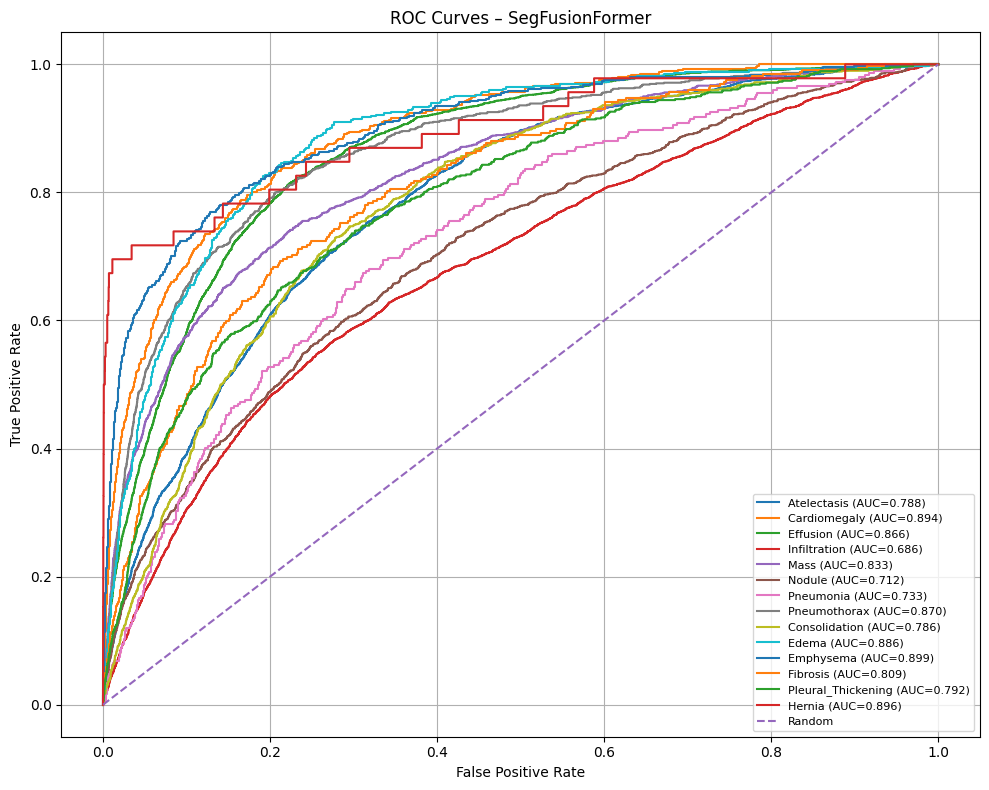

In [119]:
# ==========================================================
# Stage 4 – Step 17 : ROC Curves for All 14 Diseases
# ==========================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

for i, disease in enumerate(DISEASES):

    fpr, tpr, _ = roc_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{disease} (AUC={roc_auc:.3f})"
    )

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves – SegFusionFormer")
plt.legend(
    loc="lower right",
    fontsize=8
)

plt.grid(True)
plt.tight_layout()
plt.show()

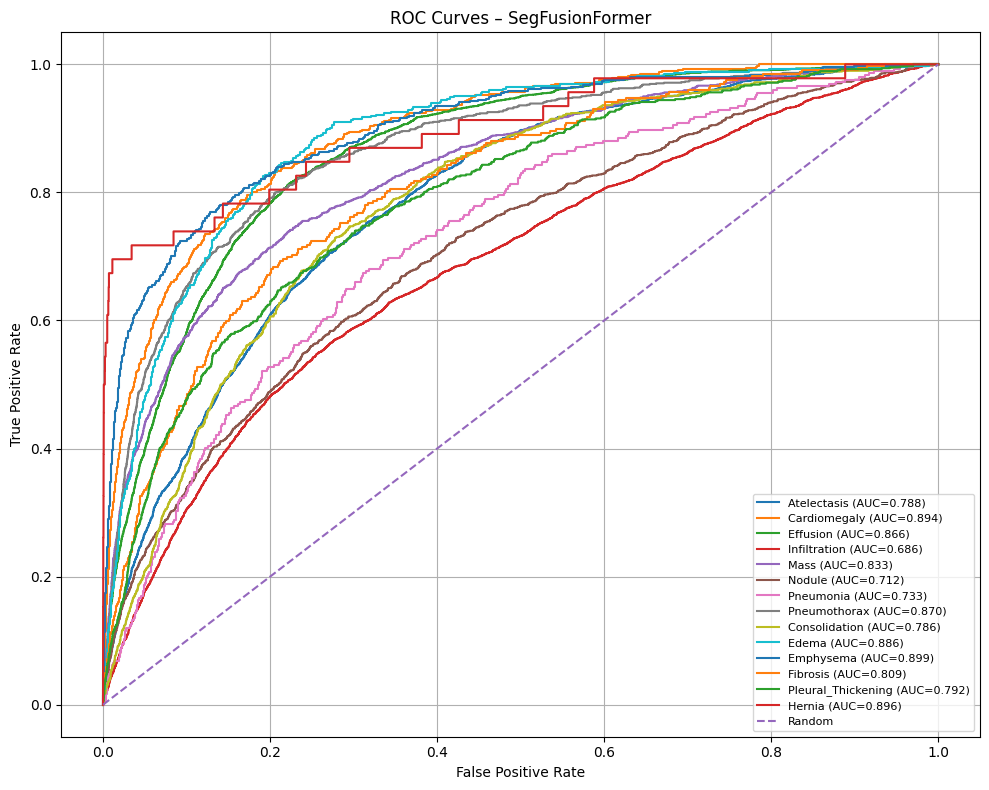

ROC figure saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/segfusionformer_roc_curves.png


In [120]:
# ==========================================================
# Stage 4 – Step 17.1 : Save ROC Figure
# ==========================================================

roc_path = outputs_dir / "segfusionformer_roc_curves.png"

plt.figure(figsize=(10, 8))

for i, disease in enumerate(DISEASES):

    fpr, tpr, _ = roc_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{disease} (AUC={roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves – SegFusionFormer")

plt.legend(
    loc="lower right",
    fontsize=8
)

plt.grid(True)
plt.tight_layout()

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC figure saved to:")
print(roc_path)

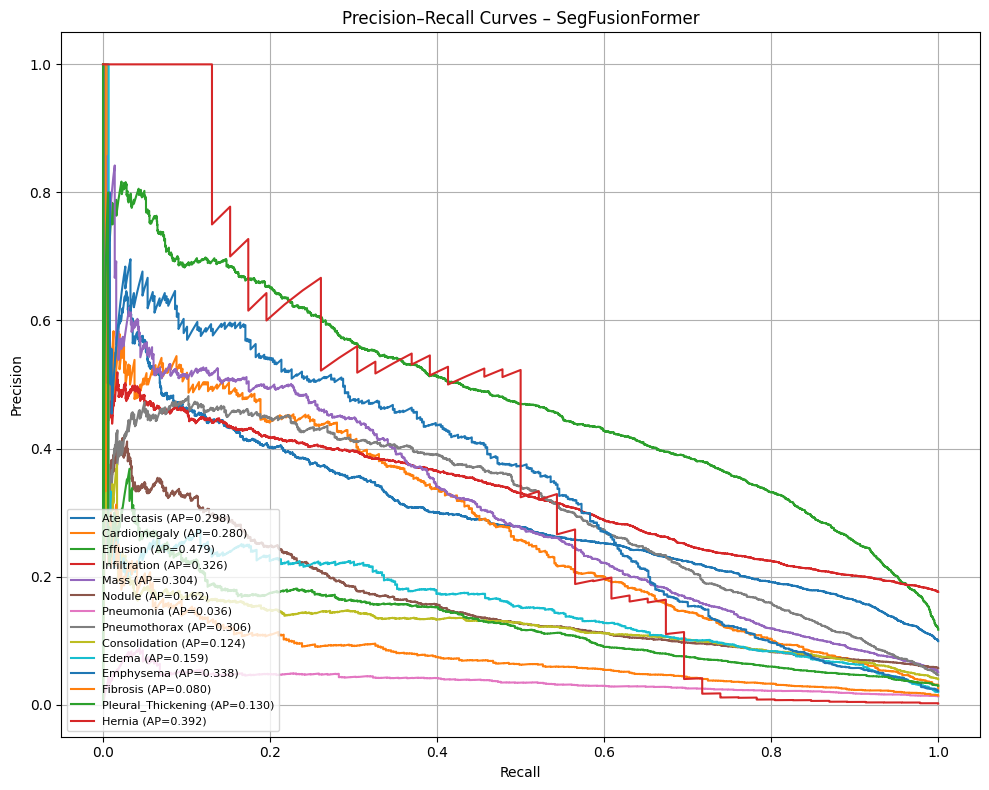

In [121]:
# ==========================================================
# Stage 4 – Step 18.1 : Precision–Recall Curves
# ==========================================================

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for i, disease in enumerate(DISEASES):

    precision, recall, _ = precision_recall_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_true[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{disease} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves – SegFusionFormer")

plt.legend(
    loc="lower left",
    fontsize=8
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [122]:
# ==========================================================
# Stage 4 – Step 18.2 : Optimal Threshold per Disease
# ==========================================================

threshold_results = []

for i, disease in enumerate(DISEASES):

    precision, recall, thresholds = precision_recall_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    # thresholds has one fewer value than precision/recall
    precision_t = precision[:-1]
    recall_t = recall[:-1]

    f1_scores = (
        2 * precision_t * recall_t
    ) / (
        precision_t + recall_t + 1e-8
    )

    best_idx = np.argmax(f1_scores)

    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]

    threshold_results.append({
        "Disease": disease,
        "Best Threshold": best_threshold,
        "Best F1": best_f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,Disease,Best Threshold,Best F1
0,Atelectasis,0.6505,0.3579
1,Cardiomegaly,0.9719,0.3690
2,Effusion,0.7342,0.5031
3,Infiltration,0.5163,0.3994
4,Mass,0.8488,0.3773
5,Nodule,0.7462,0.2329
6,Pneumonia,0.8156,0.0824
7,Pneumothorax,0.8748,0.4138
8,Consolidation,0.7302,0.2066
9,Edema,0.9483,0.2591


In [123]:
# ==========================================================
# Stage 4 – Step 18.3 : Threshold-Optimized Predictions
# ==========================================================

optimal_thresholds = threshold_df["Best Threshold"].values

y_pred_opt = np.zeros_like(
    y_prob,
    dtype=int
)

for i in range(len(DISEASES)):

    y_pred_opt[:, i] = (
        y_prob[:, i] >= optimal_thresholds[i]
    ).astype(int)

In [124]:
# ==========================================================
# Stage 4 – Step 18.4 : Compare Threshold Strategies
# ==========================================================

fixed_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

optimal_macro_f1 = f1_score(
    y_true,
    y_pred_opt,
    average="macro",
    zero_division=0
)

fixed_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

optimal_precision = precision_score(
    y_true,
    y_pred_opt,
    average="macro",
    zero_division=0
)

fixed_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

optimal_recall = recall_score(
    y_true,
    y_pred_opt,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("THRESHOLD COMPARISON")
print("=" * 70)

print("\nFixed Threshold = 0.5")
print(f"Macro F1        : {fixed_macro_f1:.4f}")
print(f"Macro Precision : {fixed_precision:.4f}")
print(f"Macro Recall    : {fixed_recall:.4f}")

print("\nOptimized Thresholds")
print(f"Macro F1        : {optimal_macro_f1:.4f}")
print(f"Macro Precision : {optimal_precision:.4f}")
print(f"Macro Recall    : {optimal_recall:.4f}")

THRESHOLD COMPARISON

Fixed Threshold = 0.5
Macro F1        : 0.2308
Macro Precision : 0.1473
Macro Recall    : 0.6866

Optimized Thresholds
Macro F1        : 0.3224
Macro Precision : 0.2742
Macro Recall    : 0.4275


In [125]:
threshold_path = (
    outputs_dir /
    "segfusionformer_optimal_thresholds.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False
)

print("Thresholds saved to:")
print(threshold_path)

Thresholds saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/segfusionformer_optimal_thresholds.csv


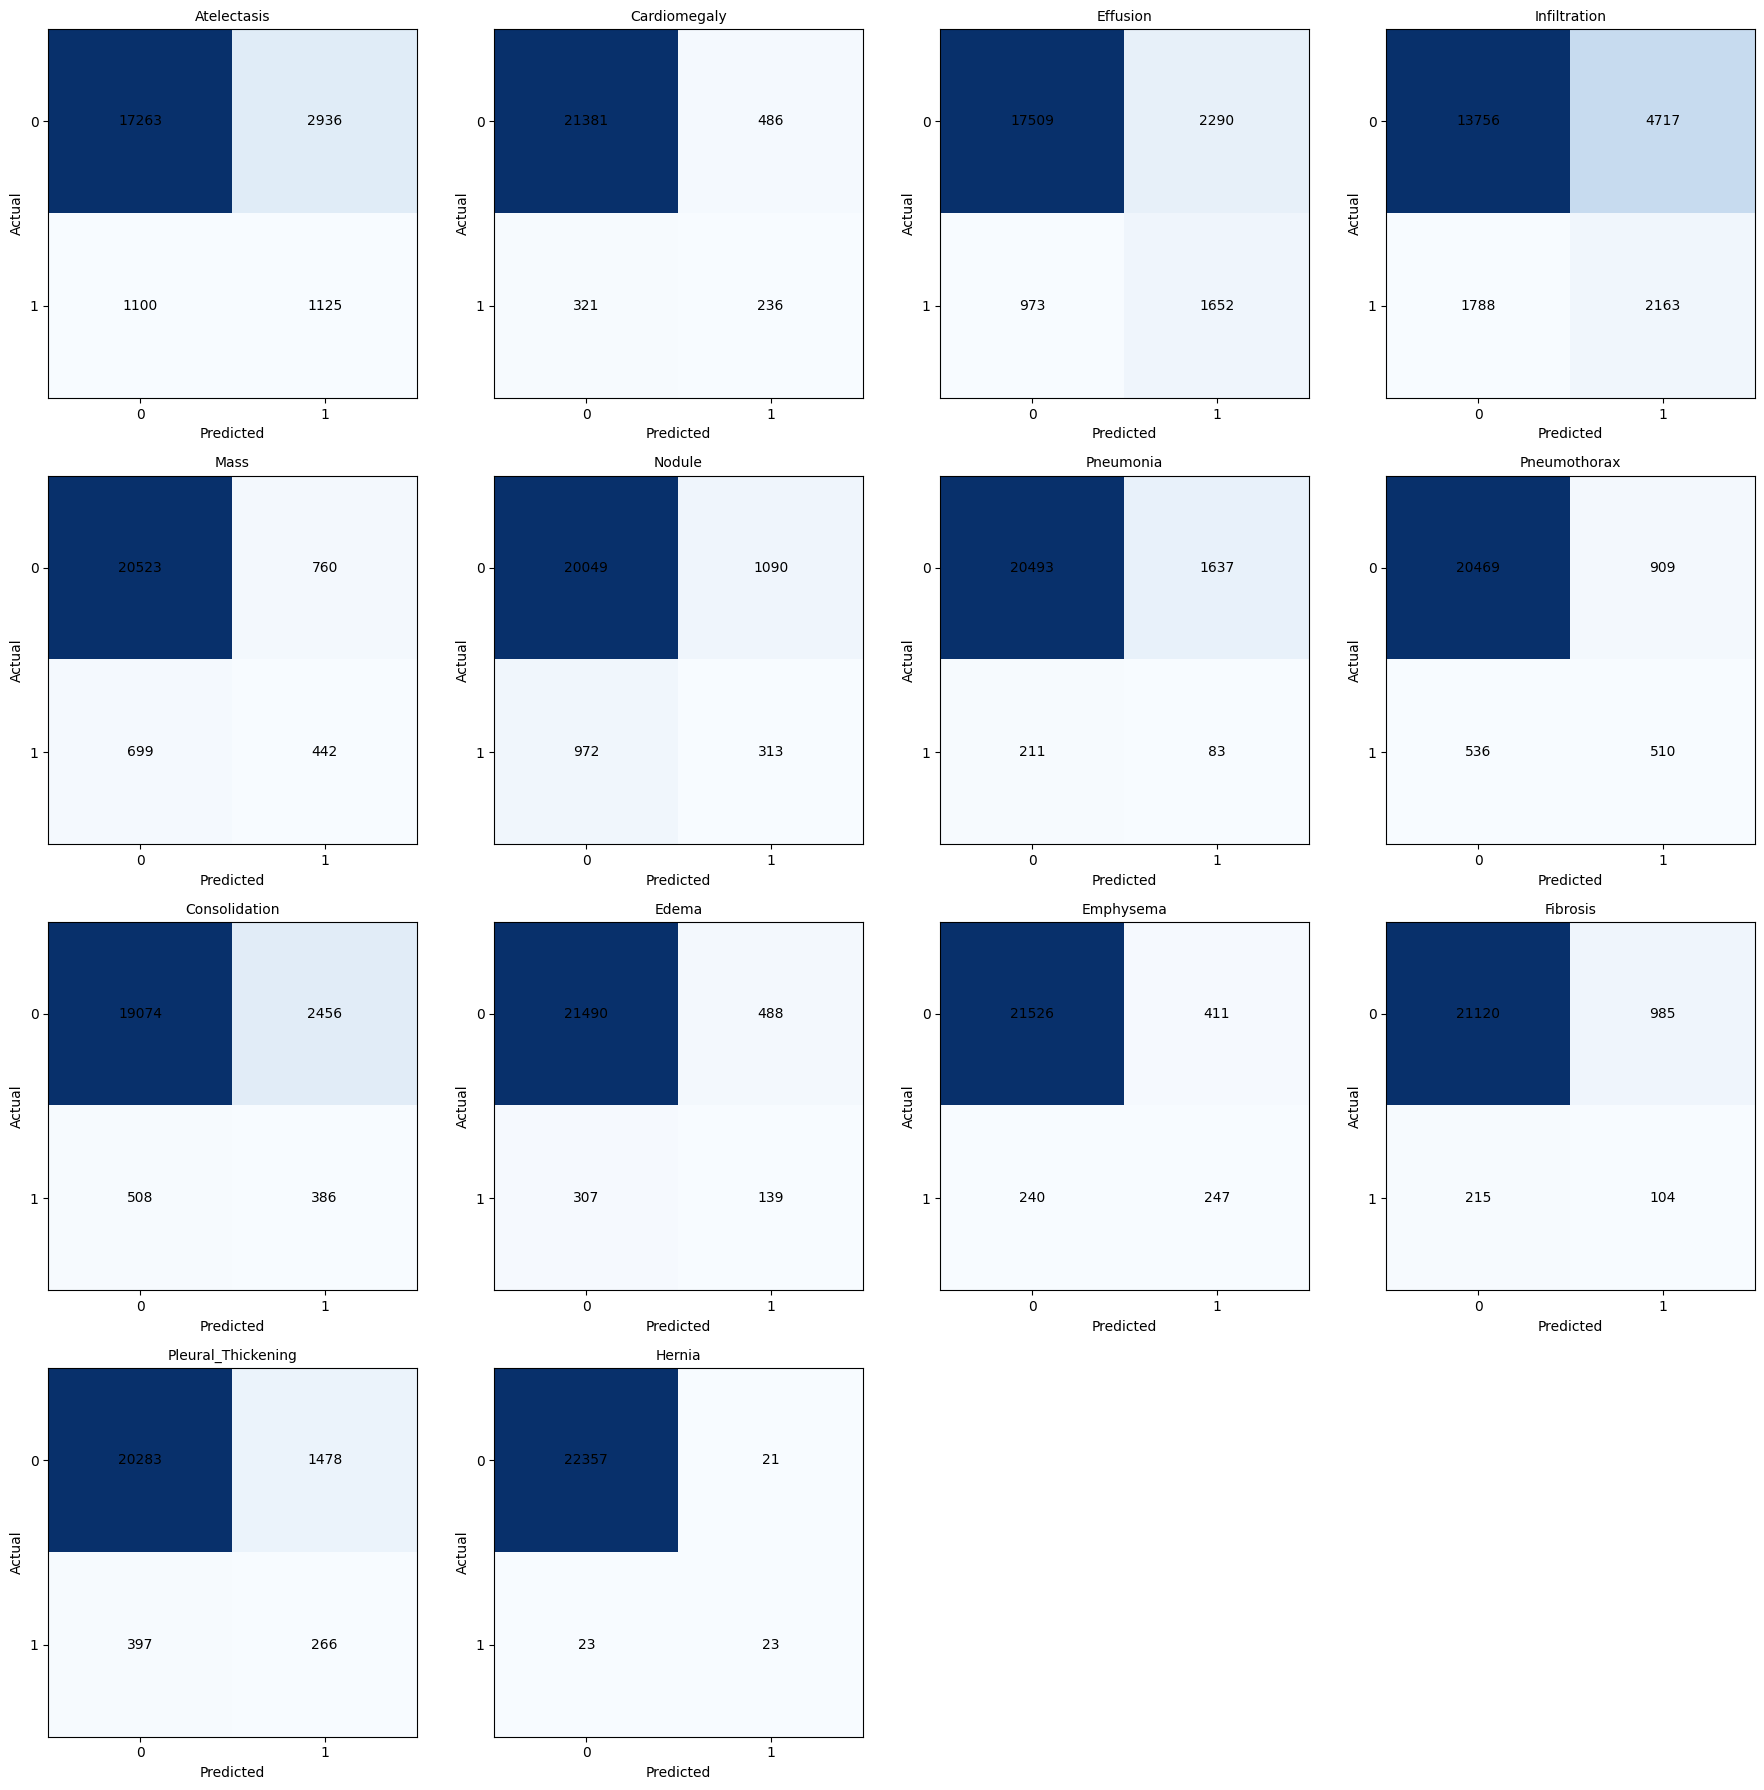

Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/confusion_matrices.png


In [128]:
# ==========================================================
# Stage 4 – Step 19.1 : Confusion Matrices (Matplotlib Only)
# ==========================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

for i, disease in enumerate(DISEASES):

    cm = confusion_matrix(
        y_true[:, i],
        y_pred_opt[:, i]
    )

    ax = axes[i]

    im = ax.imshow(cm, cmap="Blues")

    ax.set_title(disease, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["0", "1"])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["0", "1"])

    # Write values inside cells
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            ax.text(
                c,
                r,
                str(cm[r, c]),
                ha="center",
                va="center",
                color="black",
                fontsize=10
            )

# Remove unused subplot positions
for j in range(len(DISEASES), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

cm_path = outputs_dir / "confusion_matrices.png"

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", cm_path)

In [129]:
# ==========================================================
# Stage 4 – Step 19.2 : Final Metrics Table
# ==========================================================

final_metrics = results_df.copy()

final_metrics = final_metrics.round(4)

display(final_metrics)

metrics_path = outputs_dir / "final_metrics_table.csv"

final_metrics.to_csv(
    metrics_path,
    index=False
)

print("Saved:", metrics_path)

,Disease,AUROC,Precision,Recall,Specificity,F1
0,Atelectasis,0.7879,0.2242,0.6944,0.7353,0.3389
1,Cardiomegaly,0.8941,0.1165,0.7540,0.8544,0.2019
2,Effusion,0.8663,0.3318,0.8000,0.7864,0.4690
3,Infiltration,0.6857,0.3073,0.5642,0.7280,0.3979
4,Mass,0.8333,0.1862,0.6599,0.8454,0.2905
5,Nodule,0.7121,0.1208,0.5510,0.7561,0.1981
6,Pneumonia,0.7332,0.0301,0.5680,0.7564,0.0571
7,Pneumothorax,0.8698,0.1815,0.7428,0.8360,0.2917
8,Consolidation,0.7857,0.0967,0.7315,0.7164,0.1709
9,Edema,0.8862,0.0834,0.7915,0.8236,0.1510


Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/final_metrics_table.csv


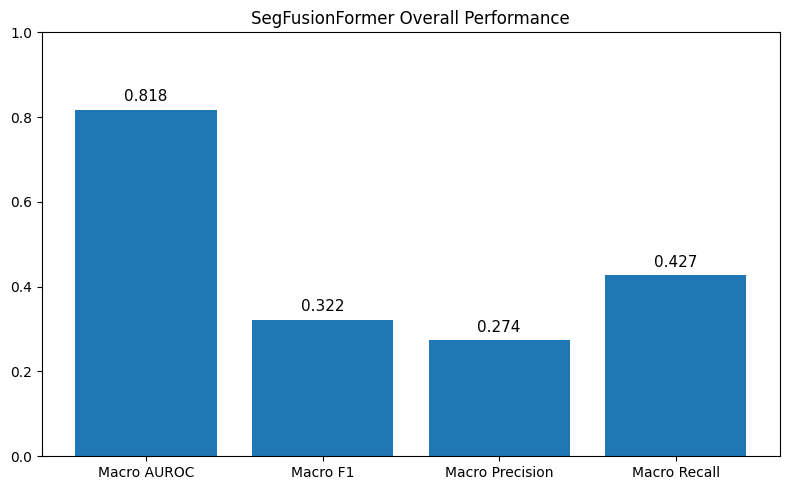

Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/overall_performance.png


In [130]:
# ==========================================================
# Stage 4 – Step 19.3 : Overall Performance Summary
# ==========================================================

summary = pd.DataFrame({

    "Metric":[
        "Macro AUROC",
        "Macro F1",
        "Macro Precision",
        "Macro Recall"
    ],

    "Value":[
        macro_auroc,
        optimal_macro_f1,
        optimal_precision,
        optimal_recall
    ]
})

plt.figure(figsize=(8,5))

plt.bar(
    summary["Metric"],
    summary["Value"]
)

plt.ylim(0,1)

for i,v in enumerate(summary["Value"]):

    plt.text(
        i,
        v+0.02,
        f"{v:.3f}",
        ha="center",
        fontsize=11
    )

plt.title("SegFusionFormer Overall Performance")

plt.tight_layout()

summary_path = outputs_dir / "overall_performance.png"

plt.savefig(
    summary_path,
    dpi=300
)

plt.show()

print("Saved:", summary_path)

In [131]:
# ==========================================================
# Stage 4 – Step 20.1 : Grad-CAM
# ==========================================================

import torch
import torch.nn.functional as F
import numpy as np


class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._forward_hook
        )

        self.backward_handle = target_layer.register_full_backward_hook(
            self._backward_hook
        )

    def _forward_hook(self, module, input, output):
        self.activations = output.detach()

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, inputs, class_index):

        # Evaluation mode
        self.model.eval()

        # Clear gradients
        self.model.zero_grad(set_to_none=True)

        # Forward pass
        logits, fusion_weights, attention_maps = self.model(inputs)

        # Target disease score
        target_score = logits[:, class_index].sum()

        # Backward pass
        target_score.backward()

        # --------------------------------------------------
        # Grad-CAM
        # --------------------------------------------------

        # Global-average-pool gradients over H and W
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted feature maps
        cam = (
            weights * self.activations
        ).sum(dim=1, keepdim=True)

        # Keep positive contributions
        cam = F.relu(cam)

        # Resize to input resolution
        cam = F.interpolate(
            cam,
            size=inputs.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Normalize independently per image
        B = cam.shape[0]

        cam_flat = cam.view(B, -1)

        cam_min = cam_flat.min(dim=1)[0].view(B, 1, 1, 1)
        cam_max = cam_flat.max(dim=1)[0].view(B, 1, 1, 1)

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        return (
            cam,
            logits.detach(),
            fusion_weights.detach(),
            attention_maps.detach()
        )

    def remove_hooks(self):

        self.forward_handle.remove()
        self.backward_handle.remove()


print("✅ Grad-CAM class created successfully.")

✅ Grad-CAM class created successfully.


In [132]:
# ==========================================================
# Stage 4 – Step 20.2 : Attach Grad-CAM Target Layer
# ==========================================================

target_layer = best_model.cnn_branch.features[-1]

gradcam = GradCAM(
    model=best_model,
    target_layer=target_layer
)

print("=" * 60)
print("Grad-CAM Initialized")
print("=" * 60)

print("Target Layer:")
print(target_layer)

Grad-CAM Initialized
Target Layer:
Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [133]:
# ==========================================================
# Stage 4 – Step 20.3 : Select Validation Sample
# ==========================================================

sample_index = None

for i in range(len(val_dataset)):

    x, label = val_dataset[i]

    if label.sum() > 0:

        sample_index = i
        break


if sample_index is None:
    raise RuntimeError("No positive validation sample found.")


sample_input, sample_label = val_dataset[sample_index]

# Add batch dimension
sample_input = sample_input.unsqueeze(0).to(device)

sample_label = sample_label.numpy()

# Select first ground-truth positive disease
positive_indices = np.where(
    sample_label == 1
)[0]

target_class = int(
    positive_indices[0]
)

target_disease = DISEASES[target_class]

print("=" * 60)
print("Grad-CAM Sample")
print("=" * 60)

print("Sample Index   :", sample_index)
print("Target Disease :", target_disease)

print("\nGround Truth Diseases:")

for i, value in enumerate(sample_label):

    if value == 1:
        print(" -", DISEASES[i])

Grad-CAM Sample
Sample Index   : 1
Target Disease : Infiltration

Ground Truth Diseases:
 - Infiltration
 - Mass
 - Nodule


In [134]:
# ==========================================================
# Stage 4 – Step 20.4 : Generate Grad-CAM Heatmap
# ==========================================================

cam, logits, fusion_weights, attention_maps = gradcam.generate(
    sample_input,
    target_class
)

probabilities = torch.sigmoid(
    logits
)

target_probability = probabilities[
    0,
    target_class
].item()

print("=" * 60)
print("Grad-CAM Generated")
print("=" * 60)

print("Disease     :", target_disease)
print(
    "Probability :",
    f"{target_probability:.4f}"
)

print(
    "CAM Shape   :",
    cam.shape
)

print(
    "CAM Range   :",
    cam.min().item(),
    "to",
    cam.max().item()
)

print("\nFusion Weights")
print(
    "CNN    :",
    fusion_weights[0, 0].item()
)

print(
    "MaxViT :",
    fusion_weights[0, 1].item()
)

Grad-CAM Generated
Disease     : Infiltration
Probability : 0.4663
CAM Shape   : torch.Size([1, 1, 224, 224])
CAM Range   : 0.0 to 0.9999997615814209

Fusion Weights
CNN    : 1.0
MaxViT : 6.897822123327815e-15


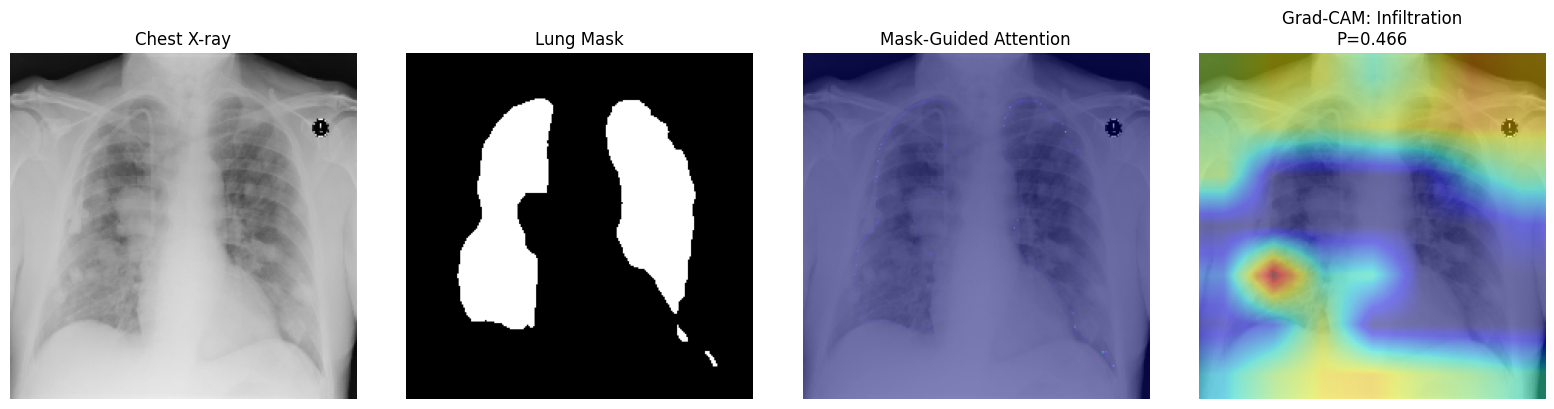

In [135]:
# ==========================================================
# Stage 4 – Step 20.5 : Visualize Grad-CAM
# ==========================================================

import matplotlib.pyplot as plt

# Extract arrays
xray = (
    sample_input[0, 0]
    .detach()
    .cpu()
    .numpy()
)

lung_mask = (
    sample_input[0, 1]
    .detach()
    .cpu()
    .numpy()
)

cam_np = (
    cam[0, 0]
    .detach()
    .cpu()
    .numpy()
)

attention_np = (
    attention_maps[0, 0]
    .detach()
    .cpu()
    .numpy()
)


plt.figure(figsize=(16, 4))

# Chest X-ray
plt.subplot(1, 4, 1)

plt.imshow(
    xray,
    cmap="gray"
)

plt.title("Chest X-ray")
plt.axis("off")


# Lung segmentation mask
plt.subplot(1, 4, 2)

plt.imshow(
    lung_mask,
    cmap="gray"
)

plt.title("Lung Mask")
plt.axis("off")


# Mask-guided attention
plt.subplot(1, 4, 3)

plt.imshow(
    xray,
    cmap="gray"
)

plt.imshow(
    attention_np,
    cmap="jet",
    alpha=0.45
)

plt.title("Mask-Guided Attention")
plt.axis("off")


# Grad-CAM
plt.subplot(1, 4, 4)

plt.imshow(
    xray,
    cmap="gray"
)

plt.imshow(
    cam_np,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM: {target_disease}\n"
    f"P={target_probability:.3f}"
)

plt.axis("off")


plt.tight_layout()
plt.show()

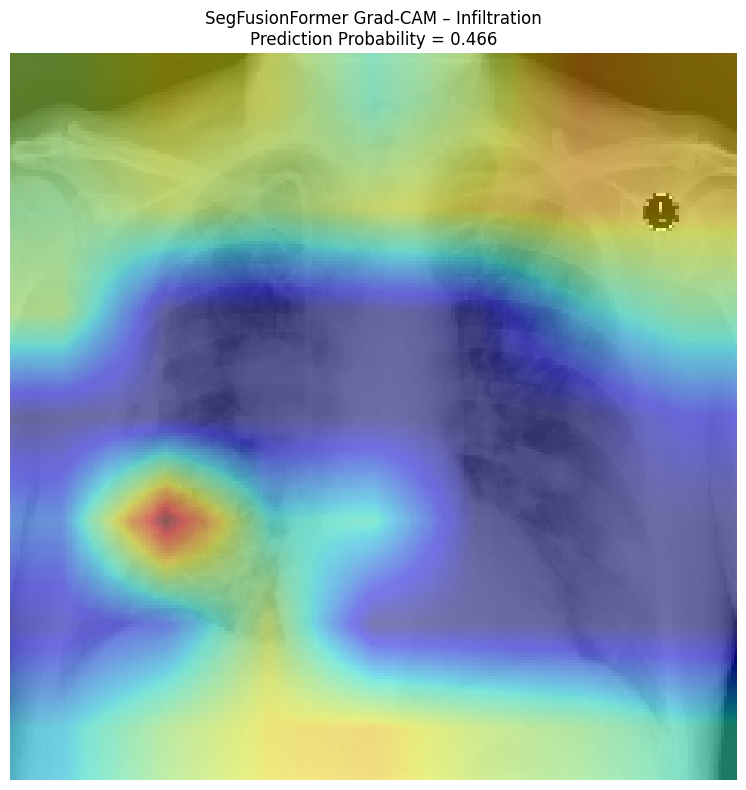

Grad-CAM saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/gradcam_Infiltration.png


In [136]:
# ==========================================================
# Stage 4 – Step 20.6 : Save Grad-CAM Figure
# ==========================================================

gradcam_path = (
    outputs_dir /
    f"gradcam_{target_disease}.png"
)

plt.figure(figsize=(8, 8))

plt.imshow(
    xray,
    cmap="gray"
)

plt.imshow(
    cam_np,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"SegFusionFormer Grad-CAM – {target_disease}\n"
    f"Prediction Probability = {target_probability:.3f}"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM saved to:")
print(gradcam_path)

In [137]:
# ==========================================================
# Stage 4 – Step 21.1 : Collect Positive Validation Samples
# ==========================================================

positive_samples = []

for i in range(len(val_dataset)):

    x, label = val_dataset[i]

    positive_indices = torch.where(label == 1)[0]

    if len(positive_indices) > 0:
        positive_samples.append(
            (i, positive_indices.tolist())
        )

    if len(positive_samples) >= 8:
        break

print("Positive validation samples found:", len(positive_samples))

for sample_idx, classes in positive_samples:
    print(
        sample_idx,
        "->",
        [DISEASES[c] for c in classes]
    )

Positive validation samples found: 8
1 -> ['Infiltration', 'Mass', 'Nodule']
5 -> ['Infiltration', 'Pneumothorax', 'Emphysema']
7 -> ['Atelectasis']
9 -> ['Effusion']
12 -> ['Nodule']
16 -> ['Mass', 'Nodule', 'Consolidation']
17 -> ['Atelectasis', 'Infiltration']
20 -> ['Effusion', 'Mass']


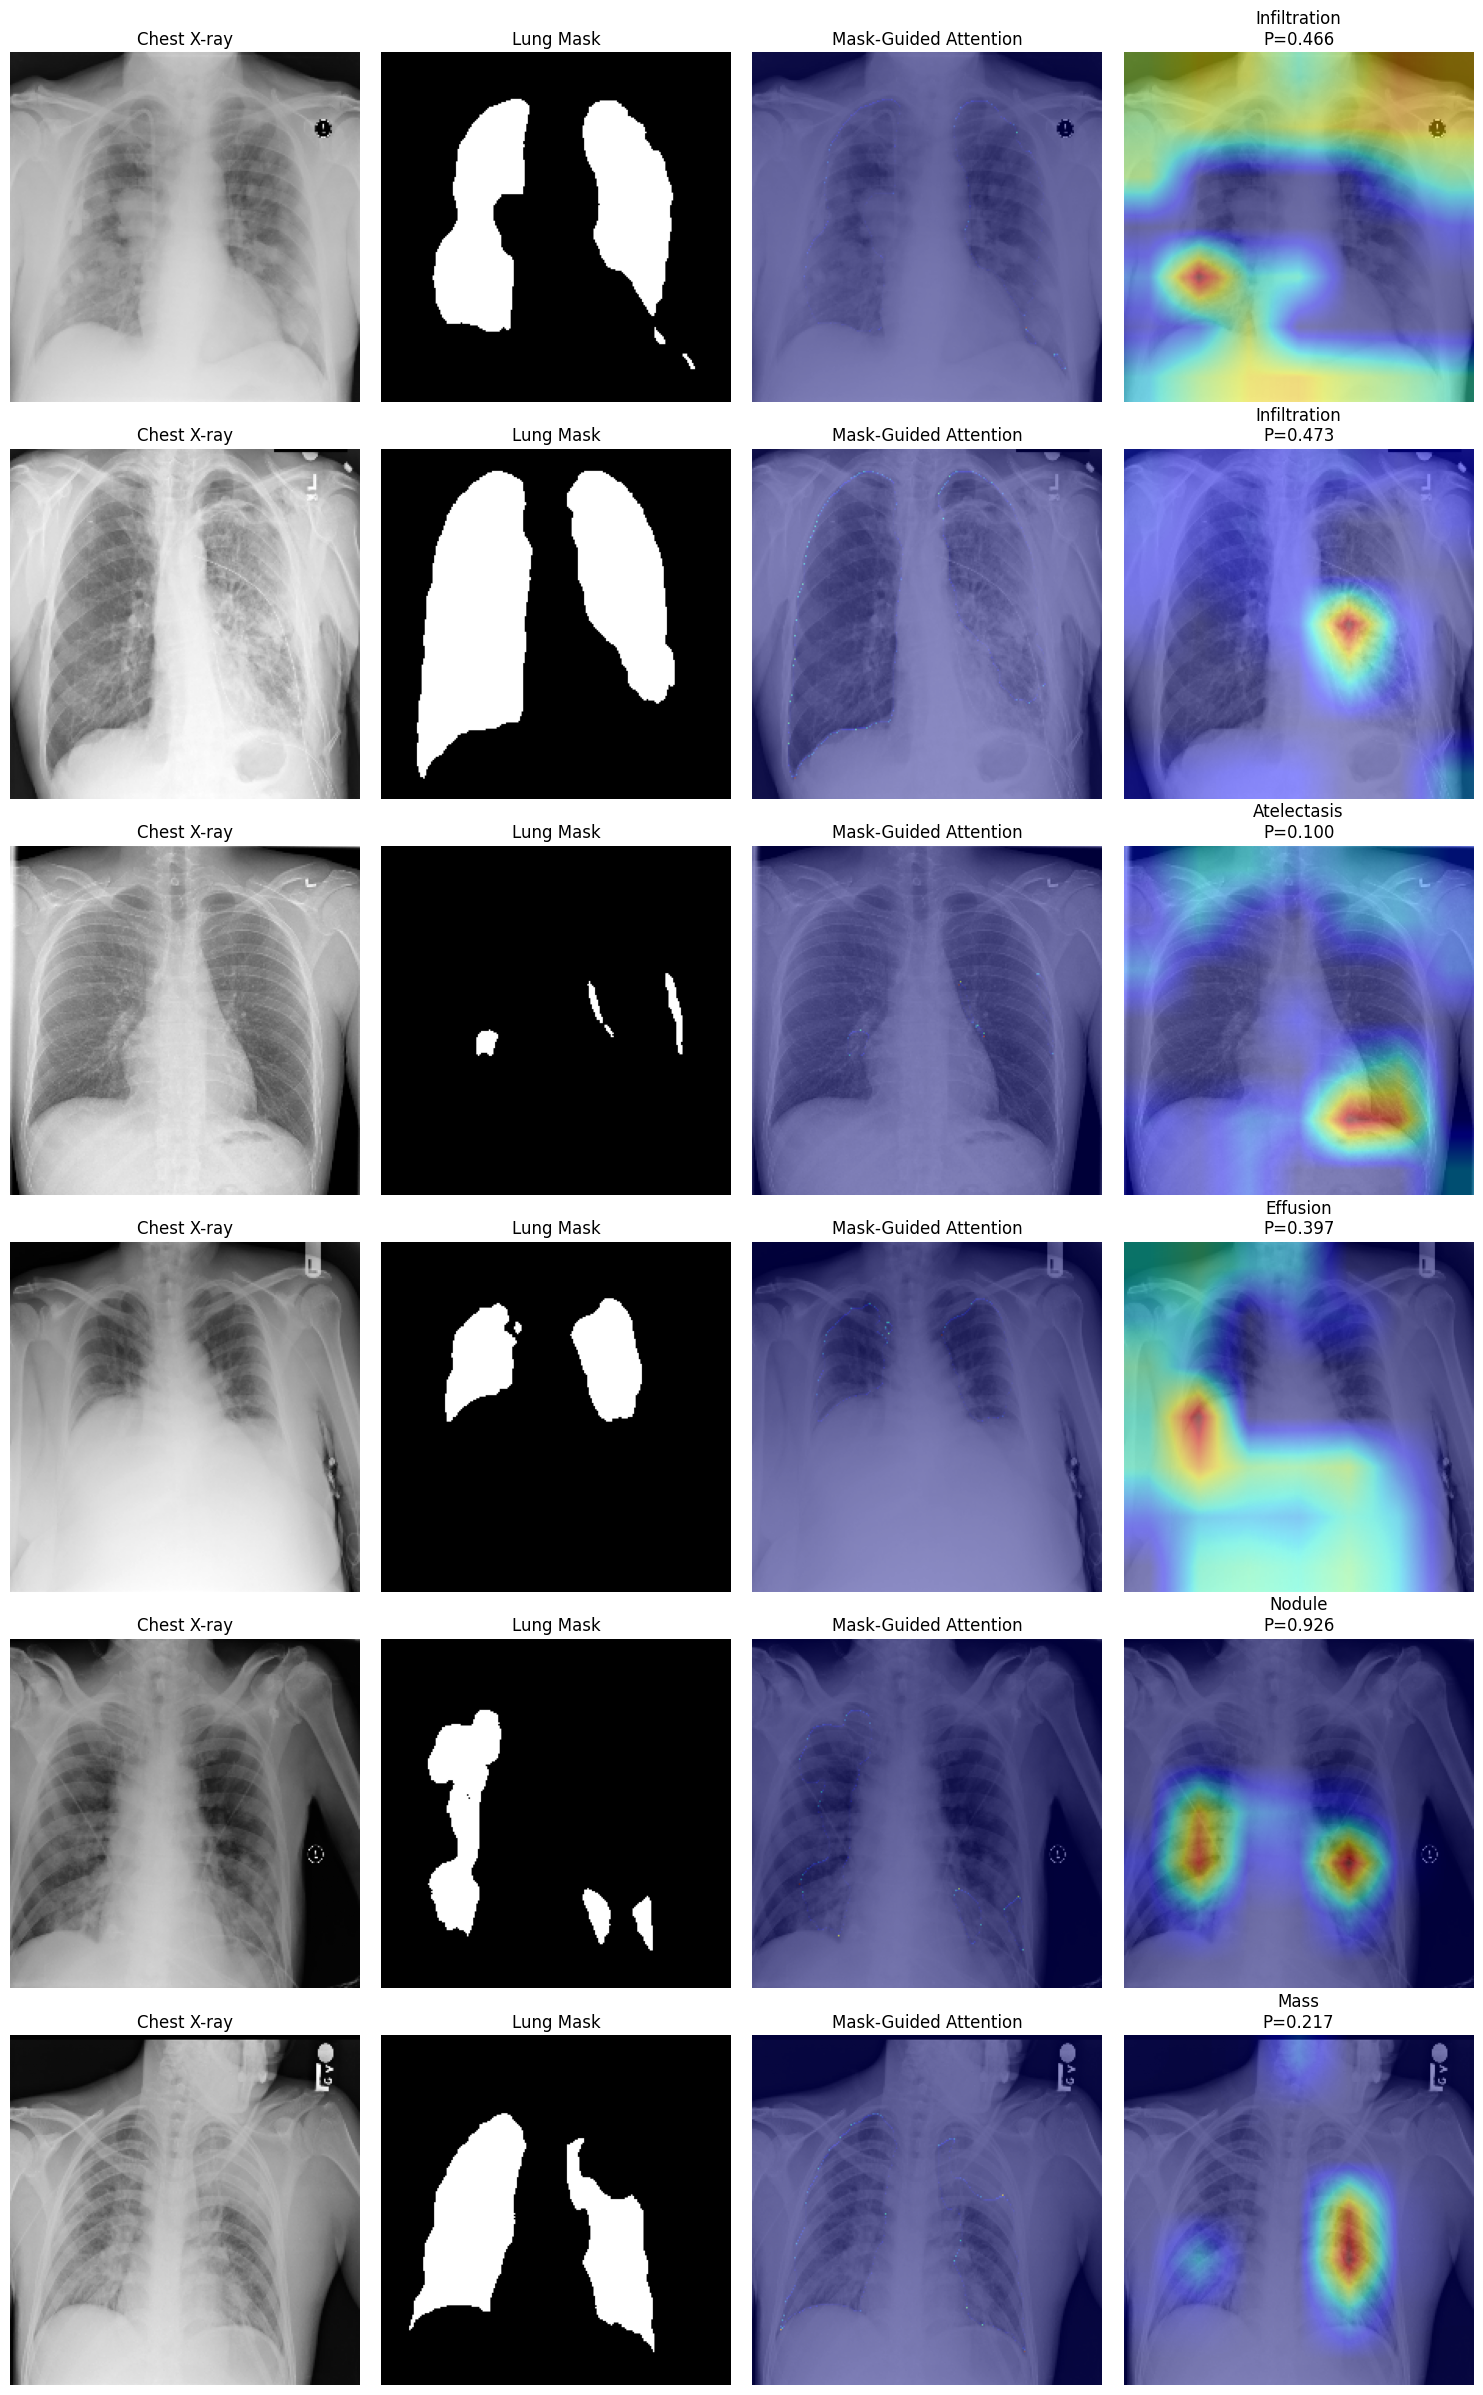

In [138]:
# ==========================================================
# Stage 4 – Step 21.2 : Multi-Sample Grad-CAM
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np

num_cases = min(6, len(positive_samples))

plt.figure(figsize=(15, 4 * num_cases))

for row_idx in range(num_cases):

    sample_idx, class_indices = positive_samples[row_idx]

    sample_input, sample_label = val_dataset[sample_idx]

    # Use first positive disease for this sample
    target_class = class_indices[0]
    target_disease = DISEASES[target_class]

    input_batch = sample_input.unsqueeze(0).to(device)

    cam, logits, fusion_weights, attention_maps = gradcam.generate(
        input_batch,
        target_class
    )

    probs = torch.sigmoid(logits)

    probability = probs[
        0,
        target_class
    ].item()

    xray = (
        input_batch[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    lung_mask = (
        input_batch[0, 1]
        .detach()
        .cpu()
        .numpy()
    )

    cam_np = (
        cam[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    attention_np = (
        attention_maps[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    # --------------------------------------------------
    # Original
    # --------------------------------------------------

    plt.subplot(num_cases, 4, row_idx * 4 + 1)

    plt.imshow(
        xray,
        cmap="gray"
    )

    plt.title("Chest X-ray")
    plt.axis("off")

    # --------------------------------------------------
    # Mask
    # --------------------------------------------------

    plt.subplot(num_cases, 4, row_idx * 4 + 2)

    plt.imshow(
        lung_mask,
        cmap="gray"
    )

    plt.title("Lung Mask")
    plt.axis("off")

    # --------------------------------------------------
    # Attention
    # --------------------------------------------------

    plt.subplot(num_cases, 4, row_idx * 4 + 3)

    plt.imshow(
        xray,
        cmap="gray"
    )

    plt.imshow(
        attention_np,
        cmap="jet",
        alpha=0.45
    )

    plt.title("Mask-Guided Attention")
    plt.axis("off")

    # --------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------

    plt.subplot(num_cases, 4, row_idx * 4 + 4)

    plt.imshow(
        xray,
        cmap="gray"
    )

    plt.imshow(
        cam_np,
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"{target_disease}\nP={probability:.3f}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [139]:
# ==========================================================
# Stage 4 – Step 21.3 : Save Multi-Case Grad-CAM Figure
# ==========================================================

multi_gradcam_path = (
    outputs_dir /
    "segfusionformer_multi_gradcam.png"
)

plt.savefig(
    multi_gradcam_path,
    dpi=300,
    bbox_inches="tight"
)

print("Saved to:")
print(multi_gradcam_path)

Saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/segfusionformer_multi_gradcam.png


<Figure size 640x480 with 0 Axes>

In [140]:
# ==========================================================
# Stage 4 – Step 22.1 : Single Image Preprocessing
# ==========================================================

def prepare_inference_input(image_path, mask_path, image_size=224):

    # Read chest X-ray
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise RuntimeError(f"Could not read image: {image_path}")

    # Read lung mask
    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        raise RuntimeError(f"Could not read mask: {mask_path}")

    # Resize
    image = cv2.resize(
        image,
        (image_size, image_size)
    )

    mask = cv2.resize(
        mask,
        (image_size, image_size),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize
    image = image.astype(np.float32) / 255.0
    mask = mask.astype(np.float32) / 255.0

    # Binary mask
    mask = (mask > 0.5).astype(np.float32)

    # Convert to tensors
    image_tensor = torch.from_numpy(image).unsqueeze(0)
    mask_tensor = torch.from_numpy(mask).unsqueeze(0)

    # Combine:
    # [2, 224, 224]
    input_tensor = torch.cat(
        [image_tensor, mask_tensor],
        dim=0
    )

    # Add batch dimension
    input_tensor = input_tensor.unsqueeze(0)

    return input_tensor, image, mask

In [141]:
# ==========================================================
# Stage 4 – Step 22.2 : Disease Prediction Function
# ==========================================================

def predict_diseases(
    model,
    image_path,
    mask_path,
    thresholds,
    device
):

    input_tensor, original_image, lung_mask = prepare_inference_input(
        image_path,
        mask_path
    )

    input_tensor = input_tensor.to(device)

    model.eval()

    with torch.no_grad():

        logits, fusion_weights, attention_maps = model(
            input_tensor
        )

        probabilities = torch.sigmoid(
            logits
        )[0].cpu().numpy()

    predictions = (
        probabilities >= thresholds
    ).astype(int)

    results = []

    for disease, prob, pred, threshold in zip(
        DISEASES,
        probabilities,
        predictions,
        thresholds
    ):

        results.append({
            "Disease": disease,
            "Probability": float(prob),
            "Threshold": float(threshold),
            "Predicted": int(pred)
        })

    results_df = pd.DataFrame(results)

    return (
        results_df,
        fusion_weights.detach().cpu(),
        attention_maps.detach().cpu(),
        original_image,
        lung_mask
    )

In [142]:
# ==========================================================
# Stage 4 – Step 22.3 : Test Inference
# ==========================================================

sample_row = val_df.iloc[0]

test_image_path = sample_row["image_path"]
test_mask_path = sample_row["mask_path"]

results_df, fusion_w, attention_map, xray_np, mask_np = predict_diseases(
    model=best_model,
    image_path=test_image_path,
    mask_path=test_mask_path,
    thresholds=optimal_thresholds,
    device=device
)

print("=" * 70)
print("SegFusionFormer Inference")
print("=" * 70)

print("Image :", test_image_path.name)

print("\nPredicted Diseases")
print("-" * 70)

positive_results = results_df[
    results_df["Predicted"] == 1
].sort_values(
    "Probability",
    ascending=False
)

display(
    positive_results[
        [
            "Disease",
            "Probability",
            "Threshold"
        ]
    ].round(4)
)

print("\nFusion Weights")

print(
    "CNN    :",
    fusion_w[0, 0].item()
)

print(
    "MaxViT :",
    fusion_w[0, 1].item()
)

SegFusionFormer Inference
Image : 00022260_003.png

Predicted Diseases
----------------------------------------------------------------------


,Disease,Probability,Threshold
7,Pneumothorax,0.9388,0.8748
2,Effusion,0.7769,0.7342
3,Infiltration,0.5986,0.5163



Fusion Weights
CNN    : 1.0
MaxViT : 1.3058732697621145e-12


In [143]:
# ==========================================================
# Stage 4 – Step 22.4 : Ground Truth Comparison
# ==========================================================

print("=" * 70)
print("Ground Truth")
print("=" * 70)

print(sample_row["Finding Labels"])

print("\nModel Predictions")
print("=" * 70)

if len(positive_results) == 0:
    print("No disease predicted above optimized thresholds.")

else:
    for _, row in positive_results.iterrows():

        print(
            f"{row['Disease']:20s} "
            f"Probability = {row['Probability']:.4f}"
        )

Ground Truth
No Finding

Model Predictions
Pneumothorax         Probability = 0.9388
Effusion             Probability = 0.7769
Infiltration         Probability = 0.5986


In [146]:
# ==========================================================
# U-Net Architecture from Notebook 03
# Required for Stage 4 End-to-End Inference
# ==========================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ----------------------------------------------------------
# Double Convolution Block
# ----------------------------------------------------------

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ----------------------------------------------------------
# Encoder / Down Block
# ----------------------------------------------------------

class Down(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)


# ----------------------------------------------------------
# Decoder / Up Block
# ----------------------------------------------------------

class Up(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

    def forward(self, x1, x2):

        # Upsample decoder feature
        x1 = self.up(x1)

        # Match skip-connection dimensions if necessary
        if x1.shape[2:] != x2.shape[2:]:

            x1 = F.interpolate(
                x1,
                size=x2.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        # Concatenate skip connection
        x = torch.cat(
            [x2, x1],
            dim=1
        )

        return self.conv(x)


# ----------------------------------------------------------
# Complete U-Net
# ----------------------------------------------------------

class UNet(nn.Module):

    def __init__(
        self,
        in_channels=1,
        out_channels=1
    ):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(
            in_channels,
            32
        )

        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)
        self.down4 = Down(256, 512)

        # Decoder
        self.up1 = Up(512, 256)
        self.up2 = Up(256, 128)
        self.up3 = Up(128, 64)
        self.up4 = Up(64, 32)

        # Final segmentation layer
        self.outc = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Decoder
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # Segmentation logits
        return self.outc(x)


print("✅ U-Net architecture loaded into Notebook 4.")

✅ U-Net architecture loaded into Notebook 4.


In [147]:
# ==========================================================
# Stage 4 – Step 23.1 : Load Trained U-Net
# ==========================================================

unet_model_path = models_dir / "best_unet.pth"

unet_model = UNet(
    in_channels=1,
    out_channels=1
).to(device)

checkpoint = torch.load(
    unet_model_path,
    map_location=device
)

unet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

unet_model.eval()

print("=" * 70)
print("Trained U-Net Loaded Successfully")
print("=" * 70)

print("Path :", unet_model_path)

print(
    "Epoch :",
    checkpoint.get("epoch", "Not stored")
)

print(
    "Validation Dice :",
    checkpoint.get("val_dice", "Not stored")
)

print(
    "Validation Loss :",
    checkpoint.get("val_loss", "Not stored")
)

print(
    "Device :",
    next(unet_model.parameters()).device
)

Trained U-Net Loaded Successfully
Path : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_unet.pth
Epoch : 14
Validation Dice : 0.9600503588544911
Validation Loss : 0.10720872776261692
Device : mps:0


In [148]:
# ==========================================================
# Stage 4 – Step 23.2 : Automatic Lung Mask Generation
# ==========================================================

def generate_lung_mask(
    image_path,
    unet_model,
    device
):

    # Read chest X-ray
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise RuntimeError(
            f"Unable to read image: {image_path}"
        )

    # U-Net input size
    image_256 = cv2.resize(
        image,
        (256, 256)
    )

    # Normalize
    image_256 = (
        image_256.astype(np.float32) / 255.0
    )

    # Tensor: [1, 1, 256, 256]
    tensor = torch.from_numpy(
        image_256
    ).unsqueeze(0).unsqueeze(0)

    tensor = tensor.to(device)

    # Predict mask
    unet_model.eval()

    with torch.no_grad():

        logits = unet_model(tensor)

        probabilities = torch.sigmoid(logits)

        predicted_mask = (
            probabilities >= 0.5
        ).float()

    # Back to NumPy
    predicted_mask = (
        predicted_mask[0, 0]
        .cpu()
        .numpy()
    )

    return image, predicted_mask


print("✅ Automatic lung-mask generation function created.")

✅ Automatic lung-mask generation function created.


In [149]:
# ==========================================================
# Stage 4 – Step 23.3 : Test Automatic Lung Segmentation
# ==========================================================

test_image_path = val_df.iloc[0]["image_path"]

original_xray, auto_mask = generate_lung_mask(
    image_path=test_image_path,
    unet_model=unet_model,
    device=device
)

print("=" * 70)
print("Automatic Lung Segmentation Test")
print("=" * 70)

print("Image :", test_image_path.name)
print("Original Shape :", original_xray.shape)
print("Mask Shape     :", auto_mask.shape)
print("Mask Values    :", np.unique(auto_mask))

Automatic Lung Segmentation Test
Image : 00022260_003.png
Original Shape : (1024, 1024)
Mask Shape     : (256, 256)
Mask Values    : [0. 1.]


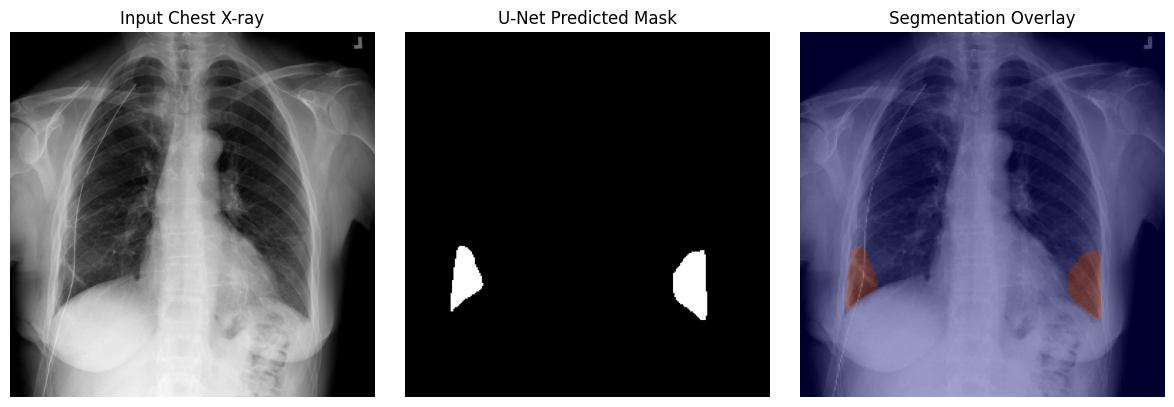

In [150]:
# ==========================================================
# Stage 4 – Step 23.4 : Visualize Automatic Lung Mask
# ==========================================================

plt.figure(figsize=(12, 4))

# Original X-ray
plt.subplot(1, 3, 1)

plt.imshow(
    original_xray,
    cmap="gray"
)

plt.title("Input Chest X-ray")
plt.axis("off")


# Predicted mask
plt.subplot(1, 3, 2)

plt.imshow(
    auto_mask,
    cmap="gray"
)

plt.title("U-Net Predicted Mask")
plt.axis("off")


# Overlay
plt.subplot(1, 3, 3)

resized_xray = cv2.resize(
    original_xray,
    (256, 256)
)

plt.imshow(
    resized_xray,
    cmap="gray"
)

plt.imshow(
    auto_mask,
    cmap="jet",
    alpha=0.35
)

plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [151]:
# ==========================================================
# Stage 4 – Step 23.2 : Automatic Lung Mask Generation
# ==========================================================

def generate_lung_mask(
    image_path,
    unet_model,
    device
):

    # Read chest X-ray
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise RuntimeError(
            f"Unable to read image: {image_path}"
        )

    # U-Net input size
    image_256 = cv2.resize(
        image,
        (256, 256)
    )

    # Normalize
    image_256 = (
        image_256.astype(np.float32) / 255.0
    )

    # Tensor: [1, 1, 256, 256]
    tensor = torch.from_numpy(
        image_256
    ).unsqueeze(0).unsqueeze(0)

    tensor = tensor.to(device)

    # Predict mask
    unet_model.eval()

    with torch.no_grad():

        logits = unet_model(tensor)

        probabilities = torch.sigmoid(logits)

        predicted_mask = (
            probabilities >= 0.5
        ).float()

    # Back to NumPy
    predicted_mask = (
        predicted_mask[0, 0]
        .cpu()
        .numpy()
    )

    return image, predicted_mask


print("✅ Automatic lung-mask generation function created.")

✅ Automatic lung-mask generation function created.


In [152]:
# ==========================================================
# Stage 4 – Step 23.3 : Test Automatic Lung Segmentation
# ==========================================================

test_image_path = val_df.iloc[0]["image_path"]

original_xray, auto_mask = generate_lung_mask(
    image_path=test_image_path,
    unet_model=unet_model,
    device=device
)

print("=" * 70)
print("Automatic Lung Segmentation Test")
print("=" * 70)

print("Image :", test_image_path.name)
print("Original Shape :", original_xray.shape)
print("Mask Shape     :", auto_mask.shape)
print("Mask Values    :", np.unique(auto_mask))

Automatic Lung Segmentation Test
Image : 00022260_003.png
Original Shape : (1024, 1024)
Mask Shape     : (256, 256)
Mask Values    : [0. 1.]


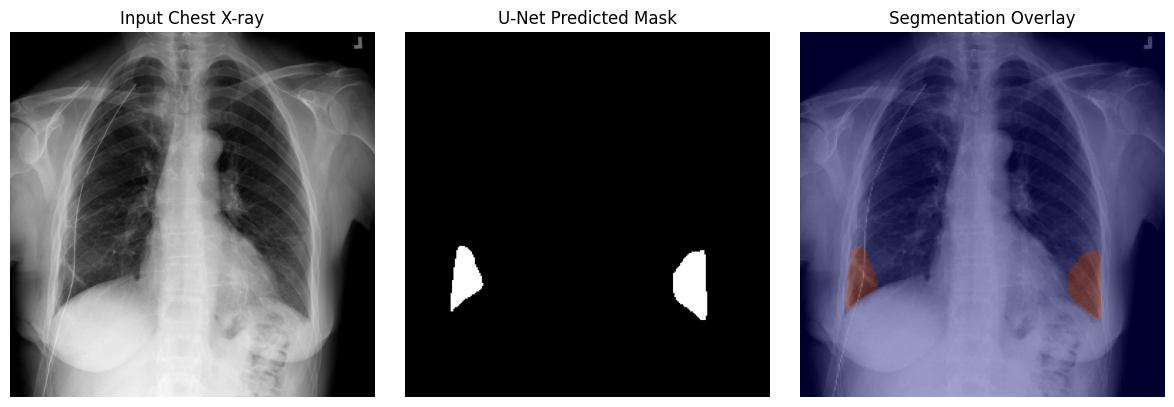

In [153]:
# ==========================================================
# Stage 4 – Step 23.4 : Visualize Automatic Lung Mask
# ==========================================================

plt.figure(figsize=(12, 4))

# Original X-ray
plt.subplot(1, 3, 1)

plt.imshow(
    original_xray,
    cmap="gray"
)

plt.title("Input Chest X-ray")
plt.axis("off")


# Predicted mask
plt.subplot(1, 3, 2)

plt.imshow(
    auto_mask,
    cmap="gray"
)

plt.title("U-Net Predicted Mask")
plt.axis("off")


# Overlay
plt.subplot(1, 3, 3)

resized_xray = cv2.resize(
    original_xray,
    (256, 256)
)

plt.imshow(
    resized_xray,
    cmap="gray"
)

plt.imshow(
    auto_mask,
    cmap="jet",
    alpha=0.35
)

plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [154]:
# ==========================================================
# Stage 4 – Step 23.5 : End-to-End Disease Prediction
# ==========================================================

def end_to_end_predict(
    image_path,
    unet_model,
    classifier,
    thresholds,
    device
):

    # --------------------------------------------------
    # 1. Generate lung mask using U-Net
    # --------------------------------------------------

    original_image, predicted_mask = generate_lung_mask(
        image_path=image_path,
        unet_model=unet_model,
        device=device
    )

    # --------------------------------------------------
    # 2. Prepare classification input at 224x224
    # --------------------------------------------------

    image_224 = cv2.resize(
        original_image,
        (224, 224)
    )

    mask_224 = cv2.resize(
        predicted_mask,
        (224, 224),
        interpolation=cv2.INTER_NEAREST
    )

    image_224 = (
        image_224.astype(np.float32) / 255.0
    )

    mask_224 = (
        mask_224 > 0.5
    ).astype(np.float32)

    # Convert to tensors
    image_tensor = torch.from_numpy(
        image_224
    ).unsqueeze(0)

    mask_tensor = torch.from_numpy(
        mask_224
    ).unsqueeze(0)

    # Combine:
    # channel 0 = X-ray
    # channel 1 = lung mask
    combined = torch.cat(
        [image_tensor, mask_tensor],
        dim=0
    )

    # Add batch dimension
    classifier_input = combined.unsqueeze(0).to(device)

    # --------------------------------------------------
    # 3. Disease prediction
    # --------------------------------------------------

    classifier.eval()

    with torch.no_grad():

        logits, fusion_weights, attention_maps = classifier(
            classifier_input
        )

        probabilities = torch.sigmoid(
            logits
        )[0].cpu().numpy()

    # --------------------------------------------------
    # 4. Apply optimized disease thresholds
    # --------------------------------------------------

    predictions = (
        probabilities >= thresholds
    ).astype(int)

    # --------------------------------------------------
    # 5. Create result table
    # --------------------------------------------------

    prediction_rows = []

    for disease, probability, threshold, prediction in zip(
        DISEASES,
        probabilities,
        thresholds,
        predictions
    ):

        prediction_rows.append({
            "Disease": disease,
            "Probability": float(probability),
            "Threshold": float(threshold),
            "Predicted": int(prediction)
        })

    prediction_df = pd.DataFrame(
        prediction_rows
    )

    return (
        prediction_df,
        image_224,
        mask_224,
        attention_maps.detach().cpu(),
        fusion_weights.detach().cpu(),
        classifier_input
    )

In [155]:
# ==========================================================
# Stage 4 – Step 23.6 : Test End-to-End Prediction
# ==========================================================

test_image_path = val_df.iloc[0]["image_path"]

(
    prediction_df,
    xray_224,
    mask_224,
    attention_map,
    fusion_weights,
    classifier_input
) = end_to_end_predict(
    image_path=test_image_path,
    unet_model=unet_model,
    classifier=best_model,
    thresholds=optimal_thresholds,
    device=device
)

print("=" * 70)
print("END-TO-END SegFusionFormer PREDICTION")
print("=" * 70)

print("Image :", test_image_path.name)

print("\nInput Shape")
print(classifier_input.shape)

print("\nFusion Weights")
print(
    "CNN    :",
    fusion_weights[0, 0].item()
)
print(
    "MaxViT :",
    fusion_weights[0, 1].item()
)

print("\nPredicted Diseases")
print("-" * 70)

positive_predictions = prediction_df[
    prediction_df["Predicted"] == 1
].sort_values(
    "Probability",
    ascending=False
)

if len(positive_predictions) == 0:
    print("No disease predicted above optimized thresholds.")
else:
    display(
        positive_predictions[
            [
                "Disease",
                "Probability",
                "Threshold"
            ]
        ].round(4)
    )

END-TO-END SegFusionFormer PREDICTION
Image : 00022260_003.png

Input Shape
torch.Size([1, 2, 224, 224])

Fusion Weights
CNN    : 1.0
MaxViT : 1.2932025242329281e-12

Predicted Diseases
----------------------------------------------------------------------


,Disease,Probability,Threshold
7,Pneumothorax,0.9387,0.8748
2,Effusion,0.7771,0.7342
3,Infiltration,0.5988,0.5163


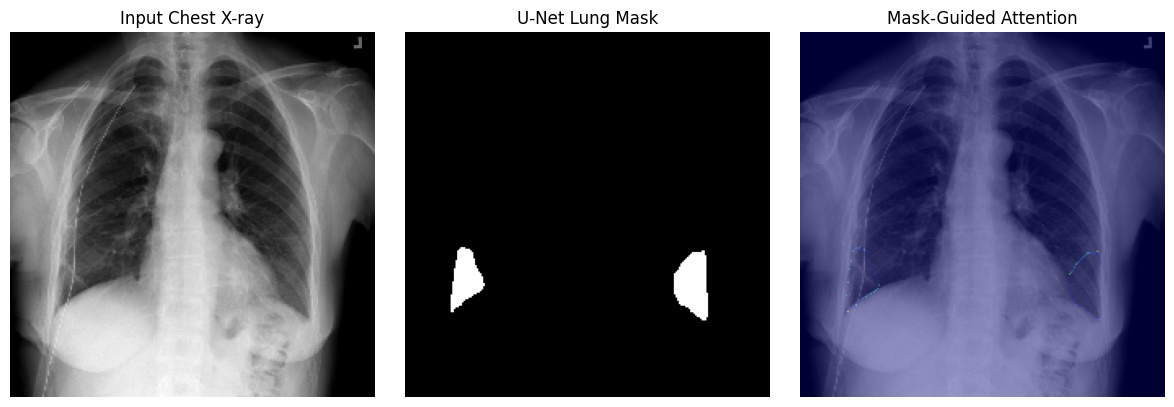

In [156]:
# ==========================================================
# Stage 4 – Step 23.7 : Visualize End-to-End Result
# ==========================================================

plt.figure(figsize=(12, 4))

# X-ray
plt.subplot(1, 3, 1)

plt.imshow(
    xray_224,
    cmap="gray"
)

plt.title("Input Chest X-ray")
plt.axis("off")


# Predicted lung mask
plt.subplot(1, 3, 2)

plt.imshow(
    mask_224,
    cmap="gray"
)

plt.title("U-Net Lung Mask")
plt.axis("off")


# Mask-guided attention
plt.subplot(1, 3, 3)

plt.imshow(
    xray_224,
    cmap="gray"
)

plt.imshow(
    attention_map[0, 0].numpy(),
    cmap="jet",
    alpha=0.40
)

plt.title("Mask-Guided Attention")
plt.axis("off")

plt.tight_layout()
plt.show()

In [157]:
# ==========================================================
# Stage 4 – Step 24.1 : End-to-End Grad-CAM Prediction
# ==========================================================

def end_to_end_gradcam(
    image_path,
    unet_model,
    classifier,
    gradcam,
    thresholds,
    device,
    target_class=None
):

    # --------------------------------------------------
    # Generate lung mask + classifier input
    # --------------------------------------------------

    (
        prediction_df,
        xray_224,
        mask_224,
        attention_map,
        fusion_weights,
        classifier_input
    ) = end_to_end_predict(
        image_path=image_path,
        unet_model=unet_model,
        classifier=classifier,
        thresholds=thresholds,
        device=device
    )

    # --------------------------------------------------
    # Choose disease for Grad-CAM
    # --------------------------------------------------

    if target_class is None:

        # Use disease with highest predicted probability
        target_class = int(
            prediction_df["Probability"].values.argmax()
        )

    target_disease = DISEASES[target_class]

    # --------------------------------------------------
    # Generate Grad-CAM
    # --------------------------------------------------

    cam, logits, fusion_w, attention_maps = gradcam.generate(
        classifier_input,
        target_class
    )

    probabilities = torch.sigmoid(logits)[0]

    target_probability = probabilities[
        target_class
    ].item()

    cam_np = (
        cam[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    return {
        "prediction_df": prediction_df,
        "xray": xray_224,
        "mask": mask_224,
        "attention": attention_maps[0, 0].cpu().numpy(),
        "gradcam": cam_np,
        "fusion_weights": fusion_w[0].cpu().numpy(),
        "target_class": target_class,
        "target_disease": target_disease,
        "target_probability": target_probability
    }

In [158]:
# ==========================================================
# Stage 4 – Step 24.2 : Test End-to-End Grad-CAM
# ==========================================================

test_image_path = val_df.iloc[0]["image_path"]

result = end_to_end_gradcam(
    image_path=test_image_path,
    unet_model=unet_model,
    classifier=best_model,
    gradcam=gradcam,
    thresholds=optimal_thresholds,
    device=device
)

print("=" * 70)
print("END-TO-END GRAD-CAM TEST")
print("=" * 70)

print("Image              :", test_image_path.name)
print("Explained Disease  :", result["target_disease"])
print(
    "Probability        :",
    f"{result['target_probability']:.4f}"
)

print("\nFusion Weights")
print(
    "CNN    :",
    result["fusion_weights"][0]
)
print(
    "MaxViT :",
    result["fusion_weights"][1]
)

END-TO-END GRAD-CAM TEST
Image              : 00022260_003.png
Explained Disease  : Pneumothorax
Probability        : 0.9387

Fusion Weights
CNN    : 1.0
MaxViT : 1.2932049e-12


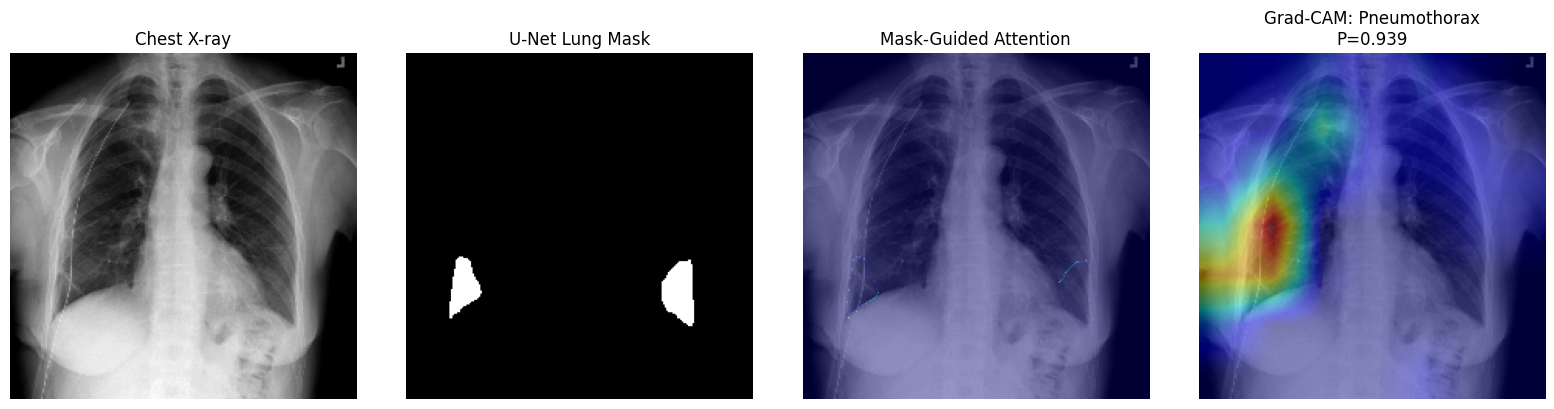

In [159]:
# ==========================================================
# Stage 4 – Step 24.3 : Final Explainable Pipeline Figure
# ==========================================================

plt.figure(figsize=(16, 4))

# Original
plt.subplot(1, 4, 1)

plt.imshow(
    result["xray"],
    cmap="gray"
)

plt.title("Chest X-ray")
plt.axis("off")


# Lung mask
plt.subplot(1, 4, 2)

plt.imshow(
    result["mask"],
    cmap="gray"
)

plt.title("U-Net Lung Mask")
plt.axis("off")


# Mask-guided attention
plt.subplot(1, 4, 3)

plt.imshow(
    result["xray"],
    cmap="gray"
)

plt.imshow(
    result["attention"],
    cmap="jet",
    alpha=0.40
)

plt.title("Mask-Guided Attention")
plt.axis("off")


# Grad-CAM
plt.subplot(1, 4, 4)

plt.imshow(
    result["xray"],
    cmap="gray"
)

plt.imshow(
    result["gradcam"],
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM: {result['target_disease']}\n"
    f"P={result['target_probability']:.3f}"
)

plt.axis("off")

plt.tight_layout()
plt.show()

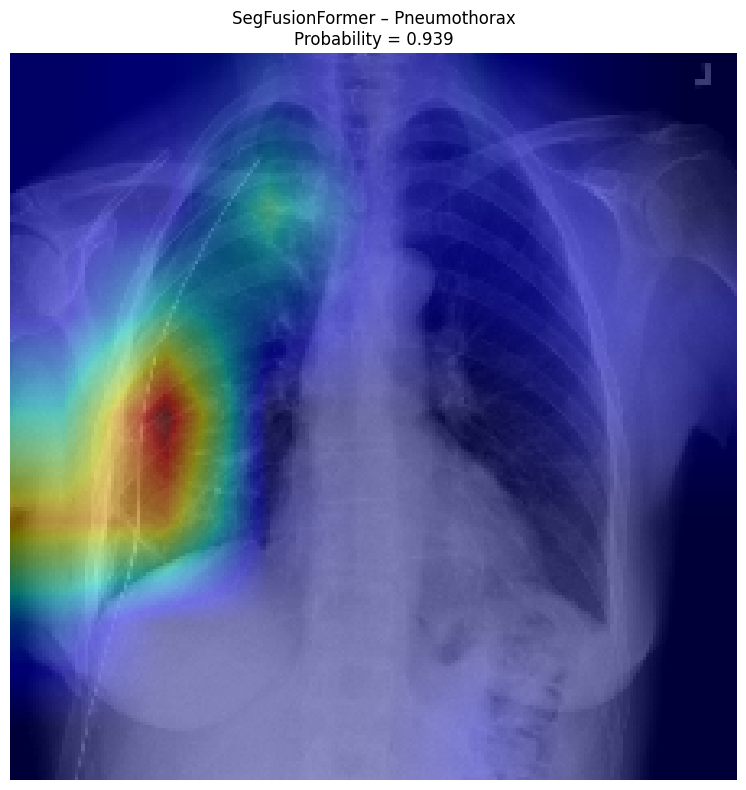

Saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/final_xai_Pneumothorax.png


In [160]:
# ==========================================================
# Stage 4 – Step 24.4 : Save Explainable Result
# ==========================================================

final_xai_path = (
    outputs_dir /
    f"final_xai_{result['target_disease']}.png"
)

plt.figure(figsize=(8, 8))

plt.imshow(
    result["xray"],
    cmap="gray"
)

plt.imshow(
    result["gradcam"],
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"SegFusionFormer – {result['target_disease']}\n"
    f"Probability = {result['target_probability']:.3f}"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    final_xai_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(final_xai_path)

In [161]:
# ==========================================================
# Stage 4 – Step 25.1 : Create Results Directories
# ==========================================================

results_dir = project_root / "results"

(results_dir / "figures").mkdir(parents=True, exist_ok=True)
(results_dir / "tables").mkdir(parents=True, exist_ok=True)
(results_dir / "models").mkdir(parents=True, exist_ok=True)

print("="*70)
print("Results Folder Created")
print("="*70)

print(results_dir)

Results Folder Created
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results


In [162]:
# ==========================================================
# Stage 4 – Step 25.2 : Save Best SegFusionFormer
# ==========================================================

import shutil

saved_model = models_dir / "best_segfusionformer.pth"

final_model = results_dir / "models" / "best_segfusionformer.pth"

shutil.copy(saved_model, final_model)

print("Saved:")
print(final_model)

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/models/best_segfusionformer.pth


In [164]:
# ==========================================================
# Stage 4 – Step 25.3 : Create Summary Dictionary
# CORRECTED VERSION
# ==========================================================

summary = {

    "Model":
        "SegFusionFormer",

    "Dataset":
        "NIH ChestX-ray14",

    "Classes":
        len(DISEASES),

    "Best Validation AUROC":
        best_auroc,

    "Threshold":
        "Optimized",

    "Batch Size":
        train_loader.batch_size,

    "Epochs":
        NUM_EPOCHS,

    "Learning Rate":
        1e-4,

    "Weight Decay":
        1e-4,

    "Backbone CNN":
        "EfficientNet-B0",

    "Backbone Transformer":
        "MaxViT-Tiny",

    "Attention":
        "Mask-Guided Attention",

    "Fusion":
        "Adaptive Feature Fusion",

    "Explainability":
        "Grad-CAM"
}

summary

{'Model': 'SegFusionFormer',
 'Dataset': 'NIH ChestX-ray14',
 'Classes': 14,
 'Best Validation AUROC': 0.8179170964320571,
 'Threshold': 'Optimized',
 'Batch Size': 8,
 'Epochs': 20,
 'Learning Rate': 0.0001,
 'Weight Decay': 0.0001,
 'Backbone CNN': 'EfficientNet-B0',
 'Backbone Transformer': 'MaxViT-Tiny',
 'Attention': 'Mask-Guided Attention',
 'Fusion': 'Adaptive Feature Fusion',
 'Explainability': 'Grad-CAM'}

In [165]:
# ==========================================================
# Stage 4 – Step 25.4 : Save Summary CSV
# ==========================================================

summary_df = pd.DataFrame([summary])

summary_csv = (
    results_dir /
    "tables" /
    "segfusionformer_summary.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False
)

print("Saved:")
print(summary_csv)

summary_df

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/segfusionformer_summary.csv


,Model,Dataset,Classes,Best Validation AUROC,Threshold,Batch Size,Epochs,Learning Rate,Weight Decay,Backbone CNN,Backbone Transformer,Attention,Fusion,Explainability
0,SegFusionFormer,NIH ChestX-ray14,14,0.817917,Optimized,8,20,0.0001,0.0001,EfficientNet-B0,MaxViT-Tiny,Mask-Guided Attention,Adaptive Feature Fusion,Grad-CAM


In [166]:
# ==========================================================
# Stage 4 – Step 25.5 : Save Optimal Thresholds
# ==========================================================

threshold_df = pd.DataFrame({

    "Disease": DISEASES,

    "Threshold": optimal_thresholds

})

threshold_path = (
    results_dir /
    "tables" /
    "optimal_thresholds.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False
)

print(threshold_df.head())

print()

print("Saved:")
print(threshold_path)

        Disease  Threshold
0   Atelectasis   0.650527
1  Cardiomegaly   0.971943
2      Effusion   0.734151
3  Infiltration   0.516267
4          Mass   0.848788

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/optimal_thresholds.csv


In [168]:
# ==========================================================
# Stage 4 – Step 25.7 : Stage 4 Completion
# ==========================================================

print("="*80)
print("SEGMENTATION-GUIDED DISEASE CLASSIFICATION COMPLETED")
print("="*80)

print()

print("Dataset")
print("-------")
print("NIH ChestX-ray14")

print()

print("Diseases")
print("--------")
print(len(DISEASES))

print()

print("Architecture")
print("------------")
print("Mask Guided Attention")
print("EfficientNet-B0")
print("MaxViT")
print("Adaptive Feature Fusion")
print("Multi-label Classification Head")

print()

print("Explainability")
print("--------------")
print("Grad-CAM")

print()

print("Best Validation AUROC")
print("---------------------")
print(f"{best_auroc:.4f}")

print()

print("Results Folder")
print("--------------")
print(results_dir)

print()

print("Stage 4 Successfully Completed.")
print("="*80)

SEGMENTATION-GUIDED DISEASE CLASSIFICATION COMPLETED

Dataset
-------
NIH ChestX-ray14

Diseases
--------
14

Architecture
------------
Mask Guided Attention
EfficientNet-B0
MaxViT
Adaptive Feature Fusion
Multi-label Classification Head

Explainability
--------------
Grad-CAM

Best Validation AUROC
---------------------
0.8179

Results Folder
--------------
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results

Stage 4 Successfully Completed.


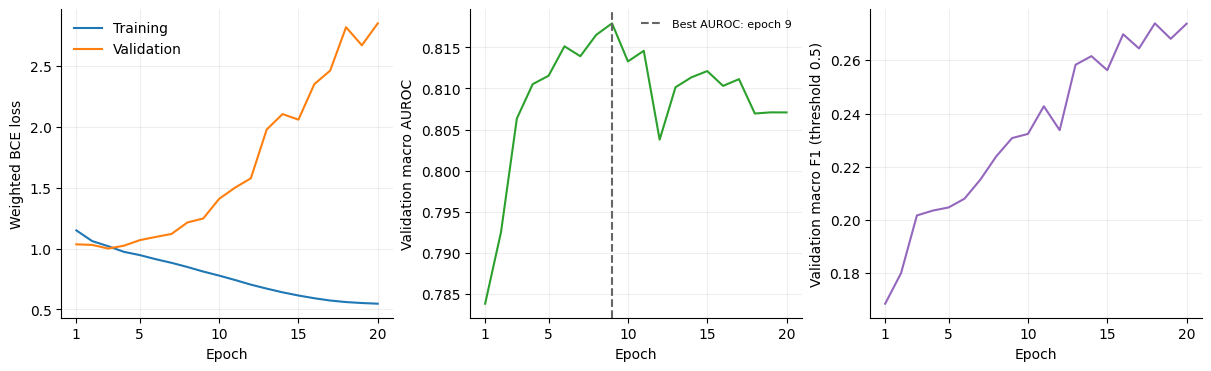

Existing live history dictionary; verify it belongs to this run.
Saved to: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/notebooks/convergence_outputs


In [169]:
"""Run in Notebook 04's live kernel, or as a script. Does not train a model."""
from pathlib import Path
import json
import re
import pandas as pd
import matplotlib.pyplot as plt

notebook_path = (Path.home() / 'Desktop' / 'Mtech_final_project' /
                 'SegFusionFormer' / 'notebooks' / '04_Disease_Classification.ipynb')
# Change this destination if desired.
curve_output_dir = Path.cwd() / 'convergence_outputs'
curve_output_dir.mkdir(parents=True, exist_ok=True)
keys = ['train_loss', 'val_loss', 'auroc', 'f1', 'precision', 'recall']

if ('history' in globals() and all(k in history for k in keys)
        and all(len(history[k]) == 20 for k in keys)):
    history_df = pd.DataFrame({k: history[k] for k in keys})
    history_df.insert(0, 'epoch', range(1, len(history_df) + 1))
    provenance = 'Existing live history dictionary; verify it belongs to this run.'
else:
    notebook = json.loads(notebook_path.read_text())
    cells = [c for c in notebook['cells']
             if 'history["train_loss"].append(train_loss)' in ''.join(c.get('source', []))]
    if len(cells) != 1:
        raise ValueError('Expected exactly one training-history cell; inspect notebook.')
    log = '\n'.join(''.join(o.get('text', [])) for o in cells[0].get('outputs', []))
    labels = dict(zip(keys, ['Train Loss', 'Val Loss', 'AUROC', 'F1 Score', 'Precision', 'Recall']))
    labels['lr_after_step'] = 'Learning Rate'
    rows = []
    for epoch, block in re.findall(r'Epoch (\d+)/20\s*(.*?)(?=Epoch \d+/20|\Z)', log, re.S):
        row = {'epoch': int(epoch)}
        for key, label in labels.items():
            match = re.search(re.escape(label) + r'\s*:\s*([0-9.]+)', block)
            if match is None:
                raise ValueError(f'Missing {label} at epoch {epoch}')
            row[key] = float(match.group(1))
        rows.append(row)
    history_df = pd.DataFrame(rows)
    if history_df['epoch'].tolist() != list(range(1, 21)):
        raise ValueError('Incomplete or duplicated epoch logs.')
    provenance = 'Recovered notebook logs: metrics rounded to 4 decimals; LR to 8 decimals.'

history_df.to_csv(curve_output_dir / 'training_history.csv', index=False)
(curve_output_dir / 'provenance.txt').write_text(provenance)
plt.rcParams.update({'font.size': 10, 'pdf.fonttype': 42, 'ps.fonttype': 42})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
epochs = history_df['epoch']
axes[0].plot(epochs, history_df['train_loss'], label='Training')
axes[0].plot(epochs, history_df['val_loss'], label='Validation')
axes[0].set_ylabel('Weighted BCE loss')
axes[0].legend(frameon=False)
axes[1].plot(epochs, history_df['auroc'], color='tab:green')
best_epoch = int(history_df.loc[history_df['auroc'].idxmax(), 'epoch'])
axes[1].axvline(best_epoch, linestyle='--', color='0.4', label=f'Best AUROC: epoch {best_epoch}')
axes[1].set_ylabel('Validation macro AUROC')
axes[1].legend(frameon=False, fontsize=8)
axes[2].plot(epochs, history_df['f1'], color='tab:purple')
axes[2].set_ylabel('Validation macro F1 (threshold 0.5)')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
fig.savefig(curve_output_dir / 'training_convergence.pdf', bbox_inches='tight')
fig.savefig(curve_output_dir / 'training_convergence.png', dpi=600, bbox_inches='tight')
plt.show()
print(provenance)
print('Saved to:', curve_output_dir.resolve())

In [170]:
train_patients = set(train_df["Patient ID"].dropna())
val_patients = set(val_df["Patient ID"].dropna())
overlap = train_patients & val_patients

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Patients in both sets:", len(overlap))
print(
    "Validation images from overlapping patients:",
    int(val_df["Patient ID"].isin(overlap).sum())
)

Training patients: 27146
Validation patients: 11687
Patients in both sets: 8028
Validation images from overlapping patients: 18542


In [172]:
# ==========================================================
# Find the NIH metadata dataframe already loaded in memory
# ==========================================================

if "nih_df" in globals():
    full_df = nih_df

elif "df" in globals():
    full_df = df

else:
    raise NameError(
        "Could not find the full NIH metadata dataframe. "
        "Please tell me the dataframe name used earlier in Notebook 04."
    )

print("Using dataframe:", full_df.shape)
print(full_df.columns.tolist()[:20])

Using dataframe: (112120, 29)
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation']


In [173]:
# ==========================================================
# PATIENT-WISE TRAIN / VALIDATION SPLIT
# ==========================================================

import numpy as np

SEED = 42
TRAIN_RATIO = 0.80

rng = np.random.default_rng(SEED)

unique_patients = (
    full_df["Patient ID"]
    .dropna()
    .unique()
)

rng.shuffle(unique_patients)

split_idx = int(
    len(unique_patients) * TRAIN_RATIO
)

train_patient_ids = set(
    unique_patients[:split_idx]
)

val_patient_ids = set(
    unique_patients[split_idx:]
)

train_df_patientwise = full_df[
    full_df["Patient ID"].isin(train_patient_ids)
].copy()

val_df_patientwise = full_df[
    full_df["Patient ID"].isin(val_patient_ids)
].copy()

print("=" * 70)
print("PATIENT-WISE DATA SPLIT")
print("=" * 70)

print("Training images   :", len(train_df_patientwise))
print("Validation images :", len(val_df_patientwise))

print(
    "Training patients :",
    train_df_patientwise["Patient ID"].nunique()
)

print(
    "Validation patients:",
    val_df_patientwise["Patient ID"].nunique()
)

PATIENT-WISE DATA SPLIT
Training images   : 90276
Validation images : 21844
Training patients : 24644
Validation patients: 6161


In [174]:
train_patients = set(
    train_df_patientwise["Patient ID"].dropna()
)

val_patients = set(
    val_df_patientwise["Patient ID"].dropna()
)

overlap = train_patients & val_patients

print(
    "Patients appearing in both sets:",
    len(overlap)
)

assert len(overlap) == 0

print(
    "✅ PASS — patient-wise split has zero overlap."
)

Patients appearing in both sets: 0
✅ PASS — patient-wise split has zero overlap.


In [175]:
# ==========================================================
# PATIENT-WISE SPLIT – CLASS DISTRIBUTION CHECK
# ==========================================================

print("=" * 90)
print("CLASS DISTRIBUTION – PATIENT-WISE SPLIT")
print("=" * 90)

distribution_rows = []

for disease in DISEASES:

    train_pos = int(
        train_df_patientwise[disease].sum()
    )

    val_pos = int(
        val_df_patientwise[disease].sum()
    )

    train_rate = (
        train_pos / len(train_df_patientwise)
    )

    val_rate = (
        val_pos / len(val_df_patientwise)
    )

    distribution_rows.append({
        "Disease": disease,
        "Train Positives": train_pos,
        "Validation Positives": val_pos,
        "Train Prevalence": train_rate,
        "Validation Prevalence": val_rate
    })

distribution_df = pd.DataFrame(
    distribution_rows
)

display(
    distribution_df.round(4)
)

CLASS DISTRIBUTION – PATIENT-WISE SPLIT


,Disease,Train Positives,Validation Positives,Train Prevalence,Validation Prevalence
0,Atelectasis,9326,2233,0.1033,0.1022
1,Cardiomegaly,2188,588,0.0242,0.0269
2,Effusion,10495,2822,0.1163,0.1292
3,Infiltration,16062,3832,0.1779,0.1754
4,Mass,4685,1097,0.0519,0.0502
5,Nodule,5134,1197,0.0569,0.0548
6,Pneumonia,1150,281,0.0127,0.0129
7,Pneumothorax,4298,1004,0.0476,0.0460
8,Consolidation,3741,926,0.0414,0.0424
9,Edema,1859,444,0.0206,0.0203


In [177]:
# ==========================================================
# RARE CLASS SAFETY CHECK
# ==========================================================

missing_train = distribution_df[
    distribution_df["Train Positives"] == 0
]

missing_val = distribution_df[
    distribution_df["Validation Positives"] == 0
]

print("=" * 70)
print("RARE CLASS CHECK")
print("=" * 70)

print(
    "Classes missing from training:",
    len(missing_train)
)

print(
    "Classes missing from validation:",
    len(missing_val)
)

if (
    len(missing_train) == 0
    and
    len(missing_val) == 0
):
    print(
        "\n✅ PASS — all 14 diseases are represented "
        "in both partitions."
    )
else:
    print(
        "\n⚠️ One or more classes require attention."
    )

RARE CLASS CHECK
Classes missing from training: 0
Classes missing from validation: 0

✅ PASS — all 14 diseases are represented in both partitions.


In [178]:
split_dir = project_root / "splits"
split_dir.mkdir(
    parents=True,
    exist_ok=True
)

train_df_patientwise.to_csv(
    split_dir / "train_patientwise_seed42.csv",
    index=False
)

val_df_patientwise.to_csv(
    split_dir / "val_patientwise_seed42.csv",
    index=False
)

print("✅ Patient-wise split saved permanently.")

✅ Patient-wise split saved permanently.


In [179]:
# ==========================================================
# Patient-wise Retraining – Step 1
# Rebuild datasets/loaders from corrected split
# ==========================================================

train_df_pw = pd.read_csv(
    split_dir / "train_patientwise_seed42.csv"
)

val_df_pw = pd.read_csv(
    split_dir / "val_patientwise_seed42.csv"
)

print("Train images:", len(train_df_pw))
print("Val images  :", len(val_df_pw))

Train images: 90276
Val images  : 21844


In [183]:
for name, obj in list(globals().items()):
    if isinstance(obj, type) and (
        "dataset" in name.lower()
        or "data" in name.lower()
    ):
        print(name)

Dataset
DataLoader
DiseaseClassificationDataset


In [184]:
# ==========================================================
# Patient-wise Retraining – Step 1
# Load corrected train / validation splits
# ==========================================================

import pandas as pd

train_df_pw = pd.read_csv(
    split_dir / "train_patientwise_seed42.csv"
)

val_df_pw = pd.read_csv(
    split_dir / "val_patientwise_seed42.csv"
)

print("=" * 70)
print("PATIENT-WISE SPLITS LOADED")
print("=" * 70)

print("Training images   :", len(train_df_pw))
print("Validation images :", len(val_df_pw))

print(
    "Training patients :",
    train_df_pw["Patient ID"].nunique()
)

print(
    "Validation patients:",
    val_df_pw["Patient ID"].nunique()
)

PATIENT-WISE SPLITS LOADED
Training images   : 90276
Validation images : 21844
Training patients : 24644
Validation patients: 6161


In [185]:
# ==========================================================
# Patient-wise Retraining – Step 2
# Create datasets using the existing exact class
# ==========================================================

train_dataset_pw = DiseaseClassificationDataset(
    train_df_pw
)

val_dataset_pw = DiseaseClassificationDataset(
    val_df_pw
)

print("=" * 70)
print("PATIENT-WISE DATASETS CREATED")
print("=" * 70)

print(
    "Train Dataset      :",
    len(train_dataset_pw)
)

print(
    "Validation Dataset :",
    len(val_dataset_pw)
)

PATIENT-WISE DATASETS CREATED
Train Dataset      : 90276
Validation Dataset : 21844


In [186]:
# ==========================================================
# Patient-wise Retraining – Step 3
# Create corrected DataLoaders
# ==========================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader_pw = DataLoader(
    train_dataset_pw,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader_pw = DataLoader(
    val_dataset_pw,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("=" * 70)
print("PATIENT-WISE DATALOADERS CREATED")
print("=" * 70)

print("Batch Size         :", BATCH_SIZE)
print("Training Batches   :", len(train_loader_pw))
print("Validation Batches :", len(val_loader_pw))

PATIENT-WISE DATALOADERS CREATED
Batch Size         : 8
Training Batches   : 11285
Validation Batches : 2731


In [187]:
# ==========================================================
# Patient-wise Retraining – Step 4
# Batch sanity check
# ==========================================================

inputs_pw, labels_pw = next(
    iter(train_loader_pw)
)

print("=" * 70)
print("PATIENT-WISE BATCH CHECK")
print("=" * 70)

print("Inputs :", inputs_pw.shape)
print("Labels :", labels_pw.shape)

print(
    "\nImage range:",
    inputs_pw[:, 0].min().item(),
    "to",
    inputs_pw[:, 0].max().item()
)

print(
    "Mask values:",
    torch.unique(
        inputs_pw[:, 1]
    )
)

PATIENT-WISE BATCH CHECK
Inputs : torch.Size([8, 2, 224, 224])
Labels : torch.Size([8, 14])

Image range: 0.0 to 0.9960784316062927
Mask values: tensor([0., 1.])


In [188]:
# ==========================================================
# Patient-wise Retraining – Step 5
# Weighted BCE from TRAINING SPLIT ONLY
# ==========================================================

import torch
import torch.nn as nn

positive_counts_pw = (
    train_df_pw[DISEASES]
    .sum()
    .values
)

negative_counts_pw = (
    len(train_df_pw)
    -
    positive_counts_pw
)

pos_weights_pw = torch.tensor(
    negative_counts_pw
    /
    positive_counts_pw,
    dtype=torch.float32,
    device=device
)

criterion_pw = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights_pw
)

print("=" * 70)
print("PATIENT-WISE WEIGHTED BCE LOSS")
print("=" * 70)

for disease, weight in zip(
    DISEASES,
    pos_weights_pw
):
    print(
        f"{disease:20s}: "
        f"{weight.item():.2f}"
    )

PATIENT-WISE WEIGHTED BCE LOSS
Atelectasis         : 8.68
Cardiomegaly        : 40.26
Effusion            : 7.60
Infiltration        : 4.62
Mass                : 18.27
Nodule              : 16.58
Pneumonia           : 77.50
Pneumothorax        : 20.00
Consolidation       : 23.13
Edema               : 47.56
Emphysema           : 41.56
Fibrosis            : 64.70
Pleural_Thickening  : 32.46
Hernia              : 461.95


In [189]:
# ==========================================================
# Patient-wise Retraining – Step 6
# Fresh SegFusionFormer
# ==========================================================

model_pw = SegFusionFormer(
    num_classes=len(DISEASES)
).to(device)

print("=" * 70)
print("FRESH PATIENT-WISE MODEL CREATED")
print("=" * 70)

print(
    "Device:",
    next(model_pw.parameters()).device
)

FRESH PATIENT-WISE MODEL CREATED
Device: mps:0


In [190]:
# ==========================================================
# Patient-wise Retraining – Step 7
# Same optimizer + scheduler
# ==========================================================

import torch.optim as optim

from torch.optim.lr_scheduler import (
    CosineAnnealingLR
)

NUM_EPOCHS = 20

optimizer_pw = optim.AdamW(
    model_pw.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_pw = CosineAnnealingLR(
    optimizer_pw,
    T_max=NUM_EPOCHS,
    eta_min=1e-6
)

use_amp_pw = (
    device.type == "cuda"
)

if use_amp_pw:
    scaler_pw = torch.cuda.amp.GradScaler()
else:
    scaler_pw = None

print("=" * 70)
print("PATIENT-WISE TRAINING CONFIGURATION")
print("=" * 70)

print("Epochs        :", NUM_EPOCHS)
print("Batch Size    :", BATCH_SIZE)
print("Learning Rate :", 1e-4)
print("Weight Decay  :", 1e-4)
print("Scheduler     : CosineAnnealingLR")
print("eta_min       :", 1e-6)
print("AMP Enabled   :", use_amp_pw)
print("Device        :", device)

PATIENT-WISE TRAINING CONFIGURATION
Epochs        : 20
Batch Size    : 8
Learning Rate : 0.0001
Weight Decay  : 0.0001
Scheduler     : CosineAnnealingLR
eta_min       : 1e-06
AMP Enabled   : False
Device        : mps


In [191]:
# ==========================================================
# Patient-wise Retraining – Step 8
# Separate checkpoint
# ==========================================================

patientwise_model_path = (
    models_dir
    /
    "best_segfusionformer_patientwise.pth"
)

print(
    "New checkpoint:",
    patientwise_model_path
)

New checkpoint: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer_patientwise.pth


In [192]:
# ==========================================================
# Patient-wise Retraining – Step 9
# History
# ==========================================================

history_pw = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "auroc": [],
    "f1": [],
    "precision": [],
    "recall": [],
    "learning_rate": []
}

best_auroc_pw = 0.0
best_epoch_pw = 0